# Natural Language Processing & Review Trust Intelligence
## AI-Powered Marketplace Trust Intelligence Platform

### Scope & Architecture
This notebook establishes the primary Natural Language Processing (NLP) trust pipeline across supported product categories and marketplaces:
1. **Canonical Platform Dataset Ingestion:** Evaluates 55,616 customer reviews joined with 27,789 canonical products across **Amazon** and **BestBuy** across all six prioritized categories (*Electronics*, *Beauty & Personal Care*, *Clothing & Fashion*, *Home & Kitchen*, *Books & Stationery*, and *Toys & Games*).
2. **Multi-Category Normalization & Global Vocabulary:** Builds leakage-safe text tokenization and TF-IDF feature representations.
3. **Rating–Sentiment Discordance Audit:** Analyzes polar discordance between numerical star ratings and text sentiment polarity using VADER; demonstrates why discordance is an exploratory signal rather than proof of fraud.
4. **Intra-Product Review Similarity & Redundancy:** Audits intra-listing review duplication and addresses combinatorial pair inflation across sparse and dense listings.
5. **Exploratory Dense Cohort Analysis:** Evaluates `dense_reviews.parquet` strictly as an exploratory high-density subset (Amazon Beauty), contrasting its density with the broader canonical dataset.
6. **Independent E-Commerce Fake Reviews Benchmark:** Evaluates the Salminen et al. (2022) 40k benchmark with duplicate-leakage prevention and proper vectorizer isolation.
7. **Research Boundary Quarantine:** Quarantines the Ott et al. hotel review experiment in `notebooks/hotel_benchmark_isolated.ipynb`, preventing domain mismatch with marketplace listings.


## 1. Primary Marketplace Data Pipeline: Canonical Ingestion & Schema Integrity
We load `canonical_reviews.parquet` as our primary review source and join `canonical_products.parquet` via `canonical_product_id`.


In [9]:
from pathlib import Path
import sys
import os
import pandas as pd
import numpy as np

project_root = Path.cwd()
if not (project_root / 'data').exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

# Load primary canonical datasets
reviews_path = project_root / 'data' / 'processed' / 'canonical_reviews.parquet'
products_path = project_root / 'data' / 'processed' / 'canonical_products.parquet'

reviews_df = pd.read_parquet(reviews_path)
products_df = pd.read_parquet(products_path)

print(f'Canonical Reviews Shape: {reviews_df.shape}')
print(f'Canonical Products Shape: {products_df.shape}')

# Verify Primary Key Uniqueness
assert reviews_df['canonical_review_id'].nunique() == len(reviews_df), 'Review primary key is not 100% unique!'
print(f'\n[PASS] Primary Key Integrity: 100% unique review IDs ({len(reviews_df):,} distinct).')

# Join Products metadata using canonical_product_id
prod_cols = ['canonical_product_id', 'category', 'subcategory', 'brand', 'title', 'price']
df = reviews_df.merge(products_df[prod_cols], on='canonical_product_id', how='left')

# Verify Referential Integrity (Foreign Key)
orphans = df['category'].isna().sum()
assert orphans == 0, f'Found {orphans} orphaned reviews referencing nonexistent products!'
print(f'[PASS] Referential Integrity: All {len(df):,} reviews link to valid products (0 foreign-key orphans).')

# Unify Timestamp Parsing (Amazon epoch seconds/ms vs. BestBuy datetime strings)
parsed_dt = pd.Series(pd.NaT, index=df.index, dtype='datetime64[ns]')
bb_mask = df['review_date'].notna()
parsed_dt[bb_mask] = pd.to_datetime(df.loc[bb_mask, 'review_date'], format='mixed')
az_s = df['timestamp'].notna() & (df['timestamp'] < 1e11)
az_ms = df['timestamp'].notna() & (df['timestamp'] >= 1e11)
parsed_dt[az_s] = pd.to_datetime(df.loc[az_s, 'timestamp'], unit='s')
parsed_dt[az_ms] = pd.to_datetime(df.loc[az_ms, 'timestamp'], unit='ms')
df['review_datetime'] = parsed_dt
print(f'[PASS] Unified Timestamps: {df["review_datetime"].notna().sum():,} parsed dates (Range: {df["review_datetime"].min().strftime("%Y-%m-%d")} to {df["review_datetime"].max().strftime("%Y-%m-%d")}).')

# Check and report text missingness
missing_text = df['review_text'].isna().sum()
empty_text = df['review_text'].astype(str).str.strip().eq('').sum()
short_text = (df['review_text'].astype(str).str.strip().str.len() < 5).sum()
print(f'[PASS] Text Completeness: {missing_text} missing, {empty_text} empty, {short_text} short (<5 chars) texts.')

# Observational Label Grounding Check
print(f'[INFO] Ground Truth Labels: {df["ground_truth_label"].isna().sum():,} / {len(df):,} reviews are unlabelled observational data.')
print('\nCanonical Reviews by Marketplace:')
display(df['marketplace'].value_counts())
print('\nCanonical Reviews by Category:')
display(df['category'].value_counts())


Canonical Reviews Shape: (55616, 15)
Canonical Products Shape: (27789, 21)

[PASS] Primary Key Integrity: 100% unique review IDs (55,616 distinct).
[PASS] Referential Integrity: All 55,616 reviews link to valid products (0 foreign-key orphans).
[PASS] Unified Timestamps: 55,616 parsed dates (Range: 2005-10-18 to 2025-02-09).
[PASS] Text Completeness: 0 missing, 0 empty, 16 short (<5 chars) texts.
[INFO] Ground Truth Labels: 55,616 / 55,616 reviews are unlabelled observational data.

Canonical Reviews by Marketplace:


marketplace
bestbuy    44965
amazon     10651
Name: count, dtype: int64


Canonical Reviews by Category:


category
Electronics               45560
Beauty & Personal Care     7525
Home & Kitchen              694
Toys & Games                663
Books & Stationery          608
Clothing & Fashion          566
Name: count, dtype: int64

## 2. Text Normalization & Multi-Category TF-IDF Vocabulary
We normalize text across all reviews (lowercasing, whitespace consolidation, stopword removal) and extract a representative TF-IDF vocabulary across all categories.


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

df['nlp_text'] = (
    df['review_text']
    .astype('string')
    .str.lower()
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

usable_df = df[df['nlp_text'].notna() & df['nlp_text'].ne('')].copy()
print(f'Total usable reviews: {len(usable_df):,}')
print(f'Unique review texts: {usable_df["nlp_text"].nunique():,}')

tfidf = TfidfVectorizer(stop_words='english', max_features=5000, ngram_range=(1, 2), min_df=5)
X_tfidf = tfidf.fit_transform(usable_df['nlp_text'])
print(f'Multi-Category TF-IDF Matrix Shape: {X_tfidf.shape}')
print(f'Vocabulary size: {len(tfidf.vocabulary_):,} features')


Total usable reviews: 55,616
Unique review texts: 44,048
Multi-Category TF-IDF Matrix Shape: (55616, 5000)
Vocabulary size: 5,000 features


## 3. Rating–Sentiment Discordance Audit (Canonical Dataset)

### Methodological Definitions
- **Polar Discordance (Standard Heuristic):** A strong directional mismatch between star rating and text polarity:
  - High rating ($r \ge 4.0$) with negative compound sentiment ($s \le -0.20$)
  - Low rating ($r \le 2.0$) with positive compound sentiment ($s \ge +0.30$)
  - Neutral ratings ($r = 3.0$) and mildly polarized text are intentionally excluded because mixed or nuanced evaluations are common on middle ratings.
- **Categorical Mismatch (Broad Definition):** Any disparity between discrete rating category ('Negative', 'Neutral', 'Positive') and sentiment bucket.

> **Key Interpretive Principle:** Rating–sentiment discordance is a weak exploratory signal for manual triage, NOT proof of deception. Legitimate causes include delivery carrier grievances, incorrect product variant shipped, polite phrasing, and sarcasm.


In [11]:
from src.nlp.review_analysis import get_sentiment_compound, is_polar_discordance

# Calculate VADER sentiment compound score for all canonical reviews
usable_df['sentiment_compound'] = usable_df['nlp_text'].apply(get_sentiment_compound)

# Categorical classifications
def rating_category(r):
    return 'Negative' if r <= 2.0 else ('Neutral' if r == 3.0 else 'Positive')

def text_sentiment_cat(s):
    return 'Positive' if s >= 0.05 else ('Negative' if s <= -0.05 else 'Neutral')

usable_df['rating_sentiment'] = usable_df['rating'].apply(rating_category)
usable_df['text_sentiment'] = usable_df['sentiment_compound'].apply(text_sentiment_cat)
usable_df['cat_mismatch'] = usable_df['rating_sentiment'] != usable_df['text_sentiment']

# Polar Discordance
usable_df['polar_discordance'] = usable_df.apply(
    lambda row: is_polar_discordance(row['rating'], row['sentiment_compound']),
    axis=1
)

print('=== SENTIMENT DISCORDANCE AUDIT RESULTS (55,616 Canonical Reviews) ===')
print(f'Polar Discordance Rate: {usable_df["polar_discordance"].sum():,} / {len(usable_df):,} ({usable_df["polar_discordance"].mean():.2%})')
print(f'Categorical Mismatch Rate: {usable_df["cat_mismatch"].sum():,} / {len(usable_df):,} ({usable_df["cat_mismatch"].mean():.2%})')
print(f'Average Sentiment Compound: {usable_df["sentiment_compound"].mean():.4f}')

print('\nRating Sentiment vs. Text Sentiment Crosstab:')
display(pd.crosstab(usable_df['rating_sentiment'], usable_df['text_sentiment'], margins=True))

print('\nPolar Discordance by Marketplace:')
for mkt, grp in usable_df.groupby('marketplace'):
    print(f'  - {mkt}: {grp["polar_discordance"].sum():,} / {len(grp):,} ({grp["polar_discordance"].mean():.2%})')

print('\nPolar Discordance by Category:')
for cat, grp in usable_df.groupby('category'):
    print(f'  - {cat}: {grp["polar_discordance"].sum():,} / {len(grp):,} ({grp["polar_discordance"].mean():.2%})')


=== SENTIMENT DISCORDANCE AUDIT RESULTS (55,616 Canonical Reviews) ===
Polar Discordance Rate: 2,590 / 55,616 (4.66%)
Categorical Mismatch Rate: 7,924 / 55,616 (14.25%)
Average Sentiment Compound: 0.6125

Rating Sentiment vs. Text Sentiment Crosstab:


text_sentiment,Negative,Neutral,Positive,All
rating_sentiment,,,,
Negative,3049,791,2059,5899
Neutral,719,277,1565,2561
Positive,1322,1468,44366,47156
All,5090,2536,47990,55616



Polar Discordance by Marketplace:
  - amazon: 672 / 10,651 (6.31%)
  - bestbuy: 1,918 / 44,965 (4.27%)

Polar Discordance by Category:
  - Beauty & Personal Care: 494 / 7,525 (6.56%)
  - Books & Stationery: 32 / 608 (5.26%)
  - Clothing & Fashion: 38 / 566 (6.71%)
  - Electronics: 1,953 / 45,560 (4.29%)
  - Home & Kitchen: 48 / 694 (6.92%)
  - Toys & Games: 25 / 663 (3.77%)


### Inspection of Representative Discordant Examples
Observing discordant examples reveals that most represent real human communication complexities rather than fraudulent manipulation.


In [12]:
print('--- High Rating (5-star) with Negative Compound (<= -0.2) ---')
sample_high_neg = usable_df[(usable_df['rating'] >= 4.0) & (usable_df['sentiment_compound'] <= -0.2)].sample(min(3, len(usable_df)), random_state=42)
for _, r in sample_high_neg.iterrows():
    print(f"[{r['marketplace'].upper()}] Category: {r['category']} | Rating: {r['rating']} stars | Compound: {r['sentiment_compound']:.2f}")
    print(f"  Text: {r['nlp_text'][:140]}...\n")

print('--- Low Rating (1-star) with Positive Compound (>= +0.3) ---')
sample_low_pos = usable_df[(usable_df['rating'] <= 2.0) & (usable_df['sentiment_compound'] >= 0.3)].sample(min(3, len(usable_df)), random_state=42)
for _, r in sample_low_pos.iterrows():
    print(f"[{r['marketplace'].upper()}] Category: {r['category']} | Rating: {r['rating']} stars | Compound: {r['sentiment_compound']:.2f}")
    print(f"  Text: {r['nlp_text'][:140]}...\n")


--- High Rating (5-star) with Negative Compound (<= -0.2) ---
[BESTBUY] Category: Electronics | Rating: 4.0 stars | Compound: -0.27
  Text: works fine until now and supports mint. the only flaws i see 'til now is that google maps collapsed once and data failed to be transported f...

[BESTBUY] Category: Electronics | Rating: 5.0 stars | Compound: -0.41
  Text: over all a great phone! nothing fancy but meet the new technology demands without much complications. perfect for someone that wants a phone...

[BESTBUY] Category: Electronics | Rating: 4.0 stars | Compound: -0.62
  Text: this phone is a very nice upgrade from my iphone 12 mini that i have had for several years now. my only complaint is that the camera is not ...

--- Low Rating (1-star) with Positive Compound (>= +0.3) ---
[BESTBUY] Category: Electronics | Rating: 1.0 stars | Compound: 0.37
  Text: did not get to use the product, as i had to return it. i bought a used iphone advertise in great condition, but when received the s

## 4. Intra-Product Review Similarity & Listing-Level Redundancy

### Review Density Reality Check
Before computing intra-product similarity, we must audit the empirical distribution of reviews per product listing across the canonical platform.


In [13]:
prod_counts = usable_df.groupby('canonical_product_id').size()
n_total_prods = len(prod_counts)
n_single_rev = (prod_counts == 1).sum()
n_multi_rev = (prod_counts >= 2).sum()

print(f'Total Canonical Products with Reviews: {n_total_prods:,}')
print(f'Products with exactly 1 review: {n_single_rev:,} ({n_single_rev / n_total_prods:.1%})')
print(f'Products with >= 2 reviews: {n_multi_rev:,} ({n_multi_rev / n_total_prods:.1%})')
print(f'Products with >= 5 reviews: {(prod_counts >= 5).sum():,} ({(prod_counts >= 5).mean():.1%})')
print(f'Products with >= 10 reviews: {(prod_counts >= 10).sum():,} ({(prod_counts >= 10).mean():.1%})')

print('\n[CRITICAL ARCHITECTURAL FINDING]')
print('84.0% of reviewed products have only 1 review. Intra-product similarity cannot be computed on single-review listings.')
print('Similarity analysis must be evaluated strictly on multi-review listings (n >= 2), avoiding misleading generalization.')


Total Canonical Products with Reviews: 3,627
Products with exactly 1 review: 3,047 (84.0%)
Products with >= 2 reviews: 580 (16.0%)
Products with >= 5 reviews: 502 (13.8%)
Products with >= 10 reviews: 469 (12.9%)

[CRITICAL ARCHITECTURAL FINDING]
84.0% of reviewed products have only 1 review. Intra-product similarity cannot be computed on single-review listings.
Similarity analysis must be evaluated strictly on multi-review listings (n >= 2), avoiding misleading generalization.


### Multi-Review Similarity Analysis & Combinatorial Explosion Audit
When multiple identical reviews appear on a listing (e.g. 5 identical reviews), calculating all pairwise combinations yields $(5 \times 4)/2 = 10$ pairs. Counting repeated pairs as independent fraud evidence creates combinatorial inflation. We report both pairwise counts and unique duplicate texts.


In [14]:
from sklearn.metrics.pairwise import cosine_similarity

multi_review_pids = prod_counts[prod_counts >= 2].index
similar_pairs = []
products_with_clusters = 0

for pid in multi_review_pids:
    group = usable_df[usable_df['canonical_product_id'] == pid]
    texts = [t for t in group['nlp_text'].tolist() if len(t) >= 10]
    if len(texts) < 2:
        continue
    eval_texts = texts[:150]  # Cap for computational efficiency
    vec = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=1, max_features=1000)
    try:
        X_sim = vec.fit_transform(eval_texts)
        sim_matrix = np.clip(cosine_similarity(X_sim), 0.0, 1.0)
        found_in_prod = False
        for i in range(len(eval_texts)):
            for j in range(i + 1, len(eval_texts)):
                score = sim_matrix[i, j]
                if score >= 0.80:
                    similar_pairs.append({
                        'canonical_product_id': pid,
                        'similarity': round(float(score), 3),
                        'review_1': eval_texts[i][:80],
                        'review_2': eval_texts[j][:80],
                        'is_exact': eval_texts[i] == eval_texts[j]
                    })
                    found_in_prod = True
        if found_in_prod:
            products_with_clusters += 1
    except Exception:
        continue

sim_df = pd.DataFrame(similar_pairs)
print(f'Total multi-review products evaluated: {len(multi_review_pids):,}')
print(f'Products with similar pairs (cosine >= 0.80): {products_with_clusters:,} ({products_with_clusters / len(multi_review_pids):.1%})')
print(f'Total pairwise similarities >= 0.80: {len(sim_df):,}')
if not sim_df.empty:
    exact_count = sim_df['is_exact'].sum()
    print(f'Exact duplicate pairs: {exact_count:,} ({exact_count / len(sim_df):.1%})')
    display(sim_df.head(6))


Total multi-review products evaluated: 580
Products with similar pairs (cosine >= 0.80): 60 (10.3%)
Total pairwise similarities >= 0.80: 286
Exact duplicate pairs: 261 (91.3%)


,canonical_product_id,similarity,review_1,review_2,is_exact
0,amazon_B000HUNBXG,1.0,four stars works great,five stars works great!,False
1,amazon_B0038A5NBA,1.0,five stars amazing product!!!,five stars amazing product!,False
2,amazon_B006GDB518,1.0,four stars good,five stars good,False
3,amazon_B00DD4KWSK,1.0,five stars great,five stars great,True
4,amazon_B00DGXXPF0,1.0,five stars love it.,five stars i love it.,False
5,amazon_B00EORAP4G,1.0,two stars too small,two stars very small,False


## 5. Exploratory Dense Cohort Analysis (Amazon Beauty Subset)

> **SCOPE NOTICE:** The dense cohort (`data/interim/dense_reviews.parquet`) contains 7,595 reviews across 300 Amazon All_Beauty products with $\ge 10$ reviews (mean 25.3 reviews/product). It is an **exploratory subset**, not representative of the broader canonical platform where 84% of products have only 1 review.


In [15]:
from src.nlp.review_analysis import ProductReviewAnalyzer

dense_path = project_root / 'data' / 'interim' / 'dense_reviews.parquet'
dense_df = pd.read_parquet(dense_path)
print(f'Dense Cohort Shape: {dense_df.shape} across {dense_df["parent_asin"].nunique()} products.')

# Run ProductReviewAnalyzer on a sample dense product
sample_asin = dense_df['parent_asin'].iloc[0]
sample_prod_reviews = dense_df[dense_df['parent_asin'] == sample_asin]

analyzer = ProductReviewAnalyzer(similarity_threshold=0.80)
summary = analyzer.analyze_reviews(sample_prod_reviews)

print(f'\nProductReviewAnalyzer Output for listing {sample_asin}:')
for k, v in summary.items():
    print(f'  {k}: {v}')


Dense Cohort Shape: (7595, 11) across 300 products.

ProductReviewAnalyzer Output for listing B09Y1B18VH:
  review_count: 40
  review_status: DENSE_MULTI_REVIEW
  average_rating: 4.62
  verified_purchase_ratio: 1.0
  average_sentiment_compound: 0.71
  empty_or_missing_text_count: 0
  max_similarity_score: 0.28
  repetitive_review_pairs: 0
  exact_duplicate_reviews: 0
  sentiment_disagreement_count: 1
  sentiment_disagreement_ratio: 0.03
  evidence_flags: []
  evidence_summary: Analyzed 40 customer reviews (avg 4.62 stars). Verified purchase ratio: 100%. Max review text similarity: 0.28. Polar sentiment-rating discordance: 3% (1/40).


## 6. Independent E-Commerce Deception Benchmark Evaluation

### Benchmark Provenance & Label Semantics
- **Dataset:** Salminen et al. (2022) / theArijitDas E-Commerce Fake Reviews Benchmark (`data/raw/benchmarks/ecommerce_fake_reviews_benchmark.parquet`).
- **Size:** 40,526 e-commerce product reviews across 10+ retail categories.
- **Labels:** `0` = Authentic customer review, `1` = Computer-generated synthetic fake review.
- **Leakage Prevention:** 33 duplicate review texts (64 records) are quarantined prior to splitting, guaranteeing **zero text overlap** between train and test partitions. The TF-IDF vectorizer is fit strictly on the training partition.


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

ecom_path = project_root / 'data' / 'raw' / 'benchmarks' / 'ecommerce_fake_reviews_benchmark.parquet'
ecom_df = pd.read_parquet(ecom_path)

print(f'E-Commerce Benchmark Raw Shape: {ecom_df.shape}')
print('Class balance:')
print(ecom_df['label'].value_counts())

# Deduplicate to strictly prevent text leakage across folds
ecom_clean = ecom_df.drop_duplicates(subset=['text']).reset_index(drop=True)
print(f'Deduplicated benchmark size: {len(ecom_clean):,} (Quarantined {len(ecom_df) - len(ecom_clean)} duplicate rows)')

# Leakage-safe Stratified 75/25 Train-Test Split
X = ecom_clean['text'].astype(str)
y = ecom_clean['label'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Verify zero leakage
overlap = len(set(X_train) & set(X_test))
assert overlap == 0, f'Leakage detected! {overlap} overlapping texts.'
print(f'Train partition: {len(X_train):,} reviews | Test partition: {len(X_test):,} reviews | Overlap: 0')

# Fit vectorizer strictly on training data
vec_bench = TfidfVectorizer(ngram_range=(1, 2), max_features=5000, stop_words='english', min_df=2)
X_train_vec = vec_bench.fit_transform(X_train)
X_test_vec = vec_bench.transform(X_test)

# Train classifier
clf = LogisticRegression(max_iter=500, random_state=42)
clf.fit(X_train_vec, y_train)

y_pred = clf.predict(X_test_vec)
y_prob = clf.predict_proba(X_test_vec)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)

print(f'\n[E-COMMERCE BENCHMARK TEST RESULTS]')
print(f'Accuracy:  {acc:.4f}')
print(f'Precision: {prec:.4f}')
print(f'Recall:    {rec:.4f}')
print(f'F1-Score:  {f1:.4f}')
print(f'ROC-AUC:   {auc:.4f}')
print(f'\nConfusion Matrix (TN, FP / FN, TP):\n{cm}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=['Authentic (0)', 'Computer-Generated (1)']))


E-Commerce Benchmark Raw Shape: (40526, 4)
Class balance:
label
1    20294
0    20232
Name: count, dtype: int64
Deduplicated benchmark size: 40,493 (Quarantined 33 duplicate rows)
Train partition: 30,369 reviews | Test partition: 10,124 reviews | Overlap: 0

[E-COMMERCE BENCHMARK TEST RESULTS]
Accuracy:  0.8785
Precision: 0.8812
Recall:    0.8752
F1-Score:  0.8782
ROC-AUC:   0.9517

Confusion Matrix (TN, FP / FN, TP):
[[4460  598]
 [ 632 4434]]

Classification Report:
                        precision    recall  f1-score   support

         Authentic (0)       0.88      0.88      0.88      5058
Computer-Generated (1)       0.88      0.88      0.88      5066

              accuracy                           0.88     10124
             macro avg       0.88      0.88      0.88     10124
          weighted avg       0.88      0.88      0.88     10124



## 7. External Domain Benchmark Quarantine Notice

> **RESEARCH BOUNDARY NOTICE:**  
> The Ott et al. hotel review deception experiment is maintained as an isolated research experiment in `notebooks/hotel_benchmark_isolated.ipynb`.
> - Hotel review deception models reflect hospitality stylometry (vacation descriptions, room cleanliness) and must **NOT** be conflated with e-commerce product fraud.
> - In accordance with governance standards, hotel labels are strictly quarantined from marketplace product listings.



## 8. Next Phase: Canonical Product-Level NLP Feature Engineering

Objective:
Convert review-level NLP signals into validated product-level features
for the marketplace trust intelligence system.

Before implementation, verify which features already exist in the
canonical datasets and reusable NLP modules.

Planned outputs:
- Review volume and rating statistics
- Verified and unverified purchase statistics
- Polar sentiment-rating discordance
- Exact duplicate review counts
- Within-product review similarity
- Listing review-density state

Products with zero reviews must be preserved.
Missing evidence must not be treated as proof of fraud.


In [17]:

from pathlib import Path

cwd = Path.cwd().resolve()

if (cwd / "data" / "processed").is_dir():
    project_root = cwd
elif (cwd.parent / "data" / "processed").is_dir():
    project_root = cwd.parent
else:
    raise FileNotFoundError(
        f"Could not locate data/processed from {cwd}"
    )

products_path = (
    project_root / "data" / "processed" / "canonical_products.parquet"
)
reviews_path = (
    project_root / "data" / "processed" / "canonical_reviews.parquet"
)

if not products_path.is_file():
    raise FileNotFoundError(f"Products dataset not found: {products_path}")

if not reviews_path.is_file():
    raise FileNotFoundError(f"Reviews dataset not found: {reviews_path}")

print("Project root:", project_root)
print("Products found:", products_path.is_file())
print("Reviews found:", reviews_path.is_file())


Project root: C:\Users\shruti\Desktop\project\ai-based-marketplace-analyzer
Products found: True
Reviews found: True


In [18]:

from pathlib import Path

cwd = Path.cwd().resolve()

if (cwd / "data" / "processed").is_dir():
    project_root = cwd
elif (cwd.parent / "data" / "processed").is_dir():
    project_root = cwd.parent
else:
    raise FileNotFoundError(
        f"Could not find data/processed from {cwd}"
    )

products_path = project_root / "data" / "processed" / "canonical_products.parquet"
reviews_path = project_root / "data" / "processed" / "canonical_reviews.parquet"

print("Project root:", project_root)
print("Products found:", products_path.is_file())
print("Reviews found:", reviews_path.is_file())


Project root: C:\Users\shruti\Desktop\project\ai-based-marketplace-analyzer
Products found: True
Reviews found: True


In [19]:

from pathlib import Path
import pandas as pd

# ============================================================
# 1. LOCATE AND LOAD CANONICAL MARKETPLACE DATASETS
# ============================================================

cwd = Path.cwd().resolve()
if (cwd / "data" / "processed").is_dir():
    project_root = cwd
elif (cwd.parent / "data" / "processed").is_dir():
    project_root = cwd.parent
else:
    raise FileNotFoundError(
        f"Could not locate data/processed from {cwd}"
    )

products_path = project_root / "data" / "processed" / "canonical_products.parquet"
reviews_path = project_root / "data" / "processed" / "canonical_reviews.parquet"

if not products_path.exists():
    raise FileNotFoundError(
        f"Products dataset not found: {products_path.resolve()}"
    )

if not reviews_path.exists():
    raise FileNotFoundError(
        f"Reviews dataset not found: {reviews_path.resolve()}"
    )

products = pd.read_parquet(products_path)
reviews = pd.read_parquet(reviews_path)

print("=" * 70)
print("CANONICAL MARKETPLACE NLP AUDIT")
print("=" * 70)

# ============================================================
# 2. PRODUCT DATA INTEGRITY
# ============================================================

print("\n" + "=" * 70)
print("PRODUCT DATA")
print("=" * 70)

print("Total product rows:", len(products))
print(
    "Unique product IDs:",
    products["canonical_product_id"].nunique()
)
print(
    "Missing product IDs:",
    products["canonical_product_id"].isna().sum()
)
print(
    "Duplicate product IDs:",
    products["canonical_product_id"].duplicated().sum()
)

# ============================================================
# 3. REVIEW DATA INTEGRITY
# ============================================================

print("\n" + "=" * 70)
print("REVIEW DATA")
print("=" * 70)

print("Total review rows:", len(reviews))
print(
    "Unique review IDs:",
    reviews["canonical_review_id"].nunique()
)
print(
    "Missing review IDs:",
    reviews["canonical_review_id"].isna().sum()
)
print(
    "Missing linked product IDs:",
    reviews["canonical_product_id"].isna().sum()
)

# ============================================================
# 4. CHECK PRODUCT-REVIEW RELATIONSHIPS
# ============================================================

product_ids = set(
    products["canonical_product_id"].dropna()
)

review_product_ids = set(
    reviews["canonical_product_id"].dropna()
)

orphan_reviews = reviews.loc[
    reviews["canonical_product_id"].notna()
    & ~reviews["canonical_product_id"].isin(product_ids)
]

products_with_reviews = len(product_ids & review_product_ids)
products_without_reviews = len(product_ids - review_product_ids)

print("\n" + "=" * 70)
print("PRODUCT-REVIEW RELATIONSHIPS")
print("=" * 70)

print("Products with at least one review:", products_with_reviews)
print("Products without reviews:", products_without_reviews)
print("Reviews linked to unknown products:", len(orphan_reviews))

# ============================================================
# 5. REVIEW COVERAGE BY MARKETPLACE
# ============================================================

print("\n" + "=" * 70)
print("REVIEWS BY MARKETPLACE")
print("=" * 70)

if "marketplace" in reviews.columns:
    print(
        reviews.groupby("marketplace", dropna=False)
        .size()
        .sort_values(ascending=False)
    )
else:
    print("Marketplace column is missing from the reviews dataset.")

# ============================================================
# 6. CHECK EXISTING FEATURE OUTPUTS
# ============================================================

print("\n" + "=" * 70)
print("EXISTING FEATURE FILES")
print("=" * 70)

feature_dir = project_root / "data" / "processed"

feature_keywords = [
    "feature",
    "nlp",
    "review",
    "sentiment",
    "similarity",
]

candidate_files = [
    path
    for path in feature_dir.glob("*.parquet")
    if any(
        keyword in path.name.lower()
        for keyword in feature_keywords
    )
]

if candidate_files:
    for path in sorted(candidate_files):
        print(f"\nFile: {path}")

        try:
            existing = pd.read_parquet(path)

            print("Shape:", existing.shape)
            print("Columns:", existing.columns.tolist())

        except Exception as exc:
            print("Could not inspect file:", exc)

else:
    print("No matching feature output files found.")

# ============================================================
# 7. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("AUDIT COMPLETE — NO DATASETS MODIFIED")
print("=" * 70)

print(f"Canonical products: {len(products):,}")
print(f"Canonical reviews: {len(reviews):,}")
print(f"Products with reviews: {products_with_reviews:,}")
print(f"Products without reviews: {products_without_reviews:,}")
print(f"Orphan reviews: {len(orphan_reviews):,}")


CANONICAL MARKETPLACE NLP AUDIT

PRODUCT DATA
Total product rows: 27789
Unique product IDs: 27789
Missing product IDs: 0
Duplicate product IDs: 0

REVIEW DATA
Total review rows: 55616
Unique review IDs: 55616
Missing review IDs: 0
Missing linked product IDs: 0

PRODUCT-REVIEW RELATIONSHIPS
Products with at least one review: 3627
Products without reviews: 24162
Reviews linked to unknown products: 0

REVIEWS BY MARKETPLACE
marketplace
bestbuy    44965
amazon     10651
dtype: int64

EXISTING FEATURE FILES

File: C:\Users\shruti\Desktop\project\ai-based-marketplace-analyzer\data\processed\canonical_reviews.parquet
Shape: (55616, 15)
Columns: ['canonical_review_id', 'source_review_id', 'canonical_product_id', 'marketplace', 'reviewer_id', 'review_title', 'review_text', 'rating', 'timestamp', 'review_date', 'verified_purchase', 'helpful_votes', 'language', 'source_provenance', 'ground_truth_label']

File: C:\Users\shruti\Desktop\project\ai-based-marketplace-analyzer\data\processed\marketplac

In [20]:

# ============================================================
# CANONICAL REVIEW FEATURE READINESS CHECK
# ============================================================

print("=" * 65)
print("CANONICAL REVIEW FEATURE READINESS")
print("=" * 65)

# 1. Inspect columns and data types
print("\nCOLUMN DATA TYPES")
print(reviews.dtypes.to_string())

# 2. Check missing values in important review fields
important_columns = [
    "canonical_review_id",
    "canonical_product_id",
    "review_text",
    "review_title",
    "rating",
    "verified_purchase",
    "language",
    "ground_truth_label",
]

available_columns = [
    col for col in important_columns if col in reviews.columns
]

print("\nMISSING VALUES IN IMPORTANT COLUMNS")
print(
    reviews[available_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

# 3. Check review-text availability
text = reviews["review_text"].fillna("").astype(str).str.strip()

print("\nREVIEW TEXT COVERAGE")
print("Empty review texts:", int(text.eq("").sum()))
print("Non-empty review texts:", int(text.ne("").sum()))
print("Text coverage (%):", round(text.ne("").mean() * 100, 2))

# 4. Check rating distribution
print("\nREVIEW RATING DISTRIBUTION")
print(reviews["rating"].value_counts(dropna=False).sort_index())

# 5. Check verified-purchase values
print("\nVERIFIED PURCHASE DISTRIBUTION")
print(reviews["verified_purchase"].value_counts(dropna=False))

# 6. Check language distribution, if available
if "language" in reviews.columns:
    print("\nTOP REVIEW LANGUAGES")
    print(reviews["language"].value_counts(dropna=False).head(15))

print("\nREADINESS CHECK COMPLETE — NO DATASETS MODIFIED")


CANONICAL REVIEW FEATURE READINESS

COLUMN DATA TYPES
canonical_review_id         str
source_review_id            str
canonical_product_id        str
marketplace                 str
reviewer_id                 str
review_title                str
review_text                 str
rating                  float64
timestamp               float64
review_date                 str
verified_purchase          bool
helpful_votes             int64
language                    str
source_provenance           str
ground_truth_label       object

MISSING VALUES IN IMPORTANT COLUMNS
ground_truth_label      55616
canonical_review_id         0
review_text                 0
canonical_product_id        0
review_title                0
rating                      0
verified_purchase           0
language                    0
dtype: int64

REVIEW TEXT COVERAGE
Empty review texts: 0
Non-empty review texts: 55616
Text coverage (%): 100.0

REVIEW RATING DISTRIBUTION
rating
1.0     4446
2.0     1453
3.0     2561
4.0

In [21]:

# ============================================================
# NLP FEATURE ENGINEERING — STEP 1
# Build the base product-level review table
# ============================================================

# Count reviews linked to each canonical product
review_counts = (
    reviews.groupby("canonical_product_id")
    .size()
    .rename("review_count")
)

# Start with ALL canonical products.
# Left join ensures products without reviews are preserved.
product_review_base = products[
    ["canonical_product_id", "marketplace", "category", "title"]
].copy()

product_review_base = product_review_base.merge(
    review_counts,
    on="canonical_product_id",
    how="left",
    validate="one_to_one",
)

# Products with no linked reviews receive a count of zero
product_review_base["review_count"] = (
    product_review_base["review_count"]
    .fillna(0)
    .astype("int64")
)

# Assign review-density state
product_review_base["listing_state"] = "DENSE_MULTI_REVIEW"

product_review_base.loc[
    product_review_base["review_count"] == 0,
    "listing_state",
] = "ZERO_REVIEWS"

product_review_base.loc[
    product_review_base["review_count"] == 1,
    "listing_state",
] = "SPARSE_SINGLE_REVIEW"

# ============================================================
# VALIDATION
# ============================================================

print("PRODUCT-LEVEL REVIEW BASE")
print("-" * 50)

print("Canonical products:", len(products))
print("Output rows:", len(product_review_base))
print(
    "Unique product IDs:",
    product_review_base["canonical_product_id"].nunique(),
)

print("\nListing-state distribution:")
print(product_review_base["listing_state"].value_counts())

print("\nReview-count summary:")
print(product_review_base["review_count"].describe())

print("\nSample output:")
display(product_review_base.head())

# Integrity checks
assert len(product_review_base) == len(products)
assert product_review_base["canonical_product_id"].is_unique
assert product_review_base["review_count"].ge(0).all()
assert product_review_base["review_count"].sum() == len(reviews)

print("\nAll base-table integrity checks passed.")


PRODUCT-LEVEL REVIEW BASE
--------------------------------------------------
Canonical products: 27789
Output rows: 27789
Unique product IDs: 27789

Listing-state distribution:
listing_state
ZERO_REVIEWS            24162
SPARSE_SINGLE_REVIEW     3047
DENSE_MULTI_REVIEW        580
Name: count, dtype: int64

Review-count summary:
count    27789.000000
mean         2.001367
std         39.522749
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       3108.000000
Name: review_count, dtype: float64

Sample output:


,canonical_product_id,marketplace,category,title,review_count,listing_state
0,amazon_B00V5CDD9C,amazon,Beauty & Personal Care,DUO-PRO From Walker Tape Co. Extension tabs pa...,28,DENSE_MULTI_REVIEW
1,amazon_B085B5S92V,amazon,Beauty & Personal Care,FZANEST Gel Nail Polish LED UV Translucent Jel...,40,DENSE_MULTI_REVIEW
2,amazon_B088G1ZJHP,amazon,Beauty & Personal Care,NuDerma FUSION Wand 4-Piece Set - Neon & Argon...,40,DENSE_MULTI_REVIEW
3,amazon_B01M1OFZOG,amazon,Beauty & Personal Care,Bed Head Curve Check Curling Wand for Tousled ...,40,DENSE_MULTI_REVIEW
4,amazon_B00JBUJ6QO,amazon,Beauty & Personal Care,Bliss Fuzz Off Bikini Fresh-scented Hair Remov...,11,DENSE_MULTI_REVIEW



All base-table integrity checks passed.


In [22]:

# ============================================================
# NLP FEATURE ENGINEERING — STEP 2
# Rating and verified-purchase features
# ============================================================

# Work with a copy of the canonical review data
review_work = reviews.copy()

# Ensure ratings are numeric; invalid or missing ratings remain NaN
review_work["rating"] = pd.to_numeric(
    review_work["rating"],
    errors="coerce",
)

# Normalize verification values while preserving unknown status
verification = review_work["verified_purchase"]

if pd.api.types.is_bool_dtype(verification):
    review_work["verification_status"] = (
        verification.map({
            True: "VERIFIED",
            False: "UNVERIFIED",
        }).fillna("UNKNOWN")
    )
else:
    normalized = verification.astype("string").str.strip().str.lower()

    review_work["verification_status"] = normalized.map({
        "true": "VERIFIED",
        "1": "VERIFIED",
        "yes": "VERIFIED",
        "false": "UNVERIFIED",
        "0": "UNVERIFIED",
        "no": "UNVERIFIED",
    }).fillna("UNKNOWN")

# Aggregate ratings and verification counts per product
rating_stats = (
    review_work.groupby("canonical_product_id")
    .agg(
        average_rating=("rating", "mean"),
        rating_std_dev=("rating", "std"),
        valid_rating_count=("rating", "count"),
    )
)

verification_stats = (
    review_work.assign(
        verified_count=lambda df: (
            df["verification_status"] == "VERIFIED"
        ).astype(int),
        unverified_count=lambda df: (
            df["verification_status"] == "UNVERIFIED"
        ).astype(int),
        known_verification_count=lambda df: (
            df["verification_status"].isin(
                ["VERIFIED", "UNVERIFIED"]
            )
        ).astype(int),
    )
    .groupby("canonical_product_id")
    .agg(
        verified_review_count=("verified_count", "sum"),
        unverified_review_count=("unverified_count", "sum"),
        known_verification_count=("known_verification_count", "sum"),
    )
)

# Merge features into our existing product-level base table
product_review_features = product_review_base.merge(
    rating_stats,
    on="canonical_product_id",
    how="left",
    validate="one_to_one",
).merge(
    verification_stats,
    on="canonical_product_id",
    how="left",
    validate="one_to_one",
)

# Products without reviews have zero review counts
count_columns = [
    "valid_rating_count",
    "verified_review_count",
    "unverified_review_count",
    "known_verification_count",
]

product_review_features[count_columns] = (
    product_review_features[count_columns]
    .fillna(0)
    .astype("int64")
)

# Ratio denominator includes only reviews with known verification status
product_review_features["verified_purchase_ratio"] = (
    product_review_features["verified_review_count"]
    / product_review_features["known_verification_count"].replace(0, np.nan)
)

# ============================================================
# VALIDATION
# ============================================================

print("RATING AND VERIFICATION FEATURES")
print("-" * 50)

display(
    product_review_features[
        [
            "canonical_product_id",
            "review_count",
            "average_rating",
            "rating_std_dev",
            "verified_review_count",
            "unverified_review_count",
            "known_verification_count",
            "verified_purchase_ratio",
        ]
    ].head(10)
)

print("\nVerification status in source reviews:")
print(review_work["verification_status"].value_counts(dropna=False))

print("\nProducts with no known verification status:")
print(
    product_review_features["verified_purchase_ratio"]
    .isna()
    .sum()
)

# Integrity checks
assert len(product_review_features) == len(products)
assert product_review_features["canonical_product_id"].is_unique

assert (
    product_review_features["verified_review_count"]
    + product_review_features["unverified_review_count"]
    <= product_review_features["review_count"]
).all()

assert product_review_features["verified_purchase_ratio"].dropna().between(0, 1).all()

print("\nRating and verification checks passed.")


RATING AND VERIFICATION FEATURES
--------------------------------------------------


,canonical_product_id,review_count,average_rating,rating_std_dev,verified_review_count,unverified_review_count,known_verification_count,verified_purchase_ratio
0,amazon_B00V5CDD9C,28,2.607143,1.892271,27,1,28,0.964286
1,amazon_B085B5S92V,40,3.975000,1.493361,37,3,40,0.925000
2,amazon_B088G1ZJHP,40,3.975000,1.609069,40,0,40,1.000000
3,amazon_B01M1OFZOG,40,4.150000,1.331088,34,6,40,0.850000
4,amazon_B00JBUJ6QO,11,2.727273,1.902152,9,2,11,0.818182
5,amazon_B00KEUT6BA,40,3.375000,1.705008,40,0,40,1.000000
6,amazon_B077TBSVK8,40,4.125000,1.522271,40,0,40,1.000000
7,amazon_B01F8AWWAW,12,4.583333,0.900337,12,0,12,1.000000
8,amazon_B08NHTHD2G,40,2.525000,1.694448,40,0,40,1.000000
9,amazon_B084QB5Q5G,40,3.750000,1.391365,39,1,40,0.975000



Verification status in source reviews:
verification_status
VERIFIED      54546
UNVERIFIED     1070
Name: count, dtype: int64

Products with no known verification status:
24162

Rating and verification checks passed.


In [23]:

# ============================================================
# NLP FEATURE ENGINEERING — STEP 3
# Rating–sentiment discordance
# ============================================================

import sys
from pathlib import Path

# Make the repository root importable from the notebooks directory
cwd = Path.cwd().resolve()
if (cwd / "data" / "processed").is_dir():
    project_root = cwd
elif (cwd.parent / "data" / "processed").is_dir():
    project_root = cwd.parent
else:
    raise FileNotFoundError(f"Could not locate project root from {cwd}")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.nlp.review_analysis import (
    get_sentiment_compound,
    is_polar_discordance,
)

# Use the canonical review data already loaded in the notebook
sentiment_work = reviews[
    ["canonical_review_id", "canonical_product_id",
     "review_text", "rating"]
].copy()

# Normalize text and ratings
sentiment_work["review_text"] = (
    sentiment_work["review_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

sentiment_work["rating"] = pd.to_numeric(
    sentiment_work["rating"],
    errors="coerce",
)

# Calculate sentiment using the existing project utility
sentiment_work["sentiment_compound"] = (
    sentiment_work["review_text"]
    .map(get_sentiment_compound)
)

# Missing ratings or empty review text should not be counted
# as eligible evidence for rating–sentiment discordance.
sentiment_work["discordance_eligible"] = (
    sentiment_work["rating"].notna()
    & sentiment_work["review_text"].str.len().ge(4)
)

sentiment_work["polar_discordance"] = False

eligible = sentiment_work["discordance_eligible"]

sentiment_work.loc[eligible, "polar_discordance"] = [
    is_polar_discordance(rating, sentiment)
    for rating, sentiment in zip(
        sentiment_work.loc[eligible, "rating"],
        sentiment_work.loc[eligible, "sentiment_compound"],
    )
]

# Aggregate eligible and discordant reviews per product
sentiment_stats = (
    sentiment_work.groupby("canonical_product_id")
    .agg(
        eligible_sentiment_review_count=(
            "discordance_eligible", "sum"
        ),
        polar_discordance_count=("polar_discordance", "sum"),
    )
)

sentiment_stats["polar_discordance_ratio"] = (
    sentiment_stats["polar_discordance_count"]
    / sentiment_stats["eligible_sentiment_review_count"].replace(
        0, np.nan
    )
)

# Merge into our existing product-level feature table
product_review_features = product_review_features.merge(
    sentiment_stats,
    on="canonical_product_id",
    how="left",
    validate="one_to_one",
)

# Products without reviews receive zero counts.
# The ratio remains NaN if no reviews are eligible.
sentiment_count_columns = [
    "eligible_sentiment_review_count",
    "polar_discordance_count",
]

product_review_features[sentiment_count_columns] = (
    product_review_features[sentiment_count_columns]
    .fillna(0)
    .astype("int64")
)

# ============================================================
# VALIDATION
# ============================================================

print("POLAR DISCORDANCE FEATURE SUMMARY")
print("-" * 50)

print("Total canonical reviews:", len(sentiment_work))
print(
    "Eligible reviews:",
    int(sentiment_work["discordance_eligible"].sum()),
)
print(
    "Polar discordant reviews:",
    int(sentiment_work["polar_discordance"].sum()),
)

display(
    product_review_features[
        [
            "canonical_product_id",
            "review_count",
            "eligible_sentiment_review_count",
            "polar_discordance_count",
            "polar_discordance_ratio",
        ]
    ].head(10)
)

assert len(product_review_features) == len(products)
assert product_review_features["canonical_product_id"].is_unique

valid_ratios = product_review_features[
    "polar_discordance_ratio"
].dropna()

assert valid_ratios.between(0, 1).all()

print("\nSentiment-discordance checks passed.")


POLAR DISCORDANCE FEATURE SUMMARY
--------------------------------------------------
Total canonical reviews: 55616
Eligible reviews: 55607
Polar discordant reviews: 2588


,canonical_product_id,review_count,eligible_sentiment_review_count,polar_discordance_count,polar_discordance_ratio
0,amazon_B00V5CDD9C,28,28,1,0.035714
1,amazon_B085B5S92V,40,40,5,0.125000
2,amazon_B088G1ZJHP,40,40,4,0.100000
3,amazon_B01M1OFZOG,40,40,2,0.050000
4,amazon_B00JBUJ6QO,11,11,1,0.090909
5,amazon_B00KEUT6BA,40,40,2,0.050000
6,amazon_B077TBSVK8,40,40,3,0.075000
7,amazon_B01F8AWWAW,12,12,0,0.000000
8,amazon_B08NHTHD2G,40,40,10,0.250000
9,amazon_B084QB5Q5G,40,40,1,0.025000



Sentiment-discordance checks passed.


In [24]:

# ============================================================
# NLP FEATURE ENGINEERING — STEP 4
# Exact duplicates and within-product similarity
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from collections import Counter
import re

SIMILARITY_THRESHOLD = 0.80
MIN_TEXT_LENGTH = 4
MAX_REVIEWS_PER_PRODUCT = 200

# Work on a copy; do not modify the canonical reviews
similarity_work = reviews[
    ["canonical_review_id", "canonical_product_id", "review_text"]
].copy()

# Normalize whitespace and case for duplicate comparison
def normalize_review_text(value):
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", str(value)).strip().casefold()

similarity_work["normalized_text"] = (
    similarity_work["review_text"].map(normalize_review_text)
)

# Empty and very short texts are excluded from duplicate/similarity analysis
similarity_work["eligible_text"] = (
    similarity_work["normalized_text"].str.len() >= MIN_TEXT_LENGTH
)

# Count duplicate occurrences beyond the first copy.
# Example: A, A, A -> 2 duplicate occurrences.
def count_duplicate_occurrences(texts):
    eligible_texts = [
        text for text in texts if len(text) >= MIN_TEXT_LENGTH
    ]
    counts = Counter(eligible_texts)
    return sum(count - 1 for count in counts.values())

exact_duplicate_stats = (
    similarity_work.groupby("canonical_product_id")["normalized_text"]
    .apply(count_duplicate_occurrences)
    .rename("exact_duplicate_review_count")
    .to_frame()
)

# Calculate maximum pairwise cosine similarity for each product.
# Similarity remains NaN if fewer than two eligible texts exist.
def calculate_product_similarity(group):
    texts = group.loc[group["eligible_text"], "normalized_text"].tolist()

    if len(texts) < 2:
        return pd.Series({
            "max_intra_listing_similarity": np.nan,
            "high_similarity_pair_count": 0,
            "similarity_pairs_evaluated": 0,
            "similarity_truncated": False,
        })

    truncated = len(texts) > MAX_REVIEWS_PER_PRODUCT
    texts = texts[:MAX_REVIEWS_PER_PRODUCT]

    try:
        vectorizer = TfidfVectorizer(
            stop_words="english",
            ngram_range=(1, 2),
            min_df=1,
            max_features=1000,
        )

        tfidf_matrix = vectorizer.fit_transform(texts)
        similarity_matrix = np.clip(cosine_similarity(tfidf_matrix), 0.0, 1.0)

        # Only examine the upper triangle: each pair once, no self-pairs
        upper_indices = np.triu_indices(len(texts), k=1)
        pair_scores = similarity_matrix[upper_indices]

        # Exclude identical normalized texts from the near-duplicate
        # pair count, so exact and near-duplicate signals stay distinct.
        exact_pair_mask = np.array([
            texts[i] == texts[j]
            for i, j in zip(*upper_indices)
        ])

        distinct_pair_scores = pair_scores[~exact_pair_mask]

        return pd.Series({
            "max_intra_listing_similarity": (
                float(pair_scores.max()) if len(pair_scores) else np.nan
            ),
            "high_similarity_pair_count": int(
                np.sum(distinct_pair_scores >= SIMILARITY_THRESHOLD)
            ),
            "similarity_pairs_evaluated": int(len(pair_scores)),
            "similarity_truncated": truncated,
        })

    except ValueError:
        # For example, all texts may contain only ignored stop words.
        return pd.Series({
            "max_intra_listing_similarity": np.nan,
            "high_similarity_pair_count": 0,
            "similarity_pairs_evaluated": 0,
            "similarity_truncated": truncated,
        })

similarity_stats = (
    similarity_work.groupby("canonical_product_id")
    .apply(calculate_product_similarity)
    .reset_index()
)

# Join exact-duplicate and similarity statistics
duplicate_similarity_stats = exact_duplicate_stats.merge(
    similarity_stats,
    on="canonical_product_id",
    how="outer",
    validate="one_to_one",
)

# Add features to the product-level table
product_review_features = product_review_features.merge(
    duplicate_similarity_stats,
    on="canonical_product_id",
    how="left",
    validate="one_to_one",
)

# Products without reviews have zero duplicate/pair counts.
# Unavailable similarity remains NaN, not zero.
count_columns = [
    "exact_duplicate_review_count",
    "high_similarity_pair_count",
    "similarity_pairs_evaluated",
]

product_review_features[count_columns] = (
    product_review_features[count_columns]
    .fillna(0)
    .astype("int64")
)

product_review_features["similarity_truncated"] = (
    product_review_features["similarity_truncated"]
    .fillna(False)
    .astype(bool)
)

# ============================================================
# VALIDATION
# ============================================================

print("DUPLICATE AND SIMILARITY SUMMARY")
print("-" * 55)

print(
    "Products with exact duplicate occurrences:",
    int((product_review_features["exact_duplicate_review_count"] > 0).sum()),
)
print(
    "Products with high-similarity distinct-text pairs:",
    int((product_review_features["high_similarity_pair_count"] > 0).sum()),
)
print(
    "Products where similarity could not be calculated:",
    int(product_review_features["max_intra_listing_similarity"].isna().sum()),
)
print(
    "Products with similarity analysis truncated:",
    int(product_review_features["similarity_truncated"].sum()),
)

display(
    product_review_features[
        [
            "canonical_product_id",
            "review_count",
            "exact_duplicate_review_count",
            "max_intra_listing_similarity",
            "high_similarity_pair_count",
            "similarity_pairs_evaluated",
            "similarity_truncated",
        ]
    ].head(10)
)

assert len(product_review_features) == len(products)
assert product_review_features["canonical_product_id"].is_unique
assert product_review_features["exact_duplicate_review_count"].ge(0).all()
assert product_review_features["high_similarity_pair_count"].ge(0).all()

print("\nDuplicate and similarity checks passed.")


DUPLICATE AND SIMILARITY SUMMARY
-------------------------------------------------------
Products with exact duplicate occurrences: 68
Products with high-similarity distinct-text pairs: 32
Products where similarity could not be calculated: 27209
Products with similarity analysis truncated: 52


,canonical_product_id,review_count,exact_duplicate_review_count,max_intra_listing_similarity,high_similarity_pair_count,similarity_pairs_evaluated,similarity_truncated
0,amazon_B00V5CDD9C,28,0,0.288861,0,378,False
1,amazon_B085B5S92V,40,0,0.255056,0,780,False
2,amazon_B088G1ZJHP,40,0,0.321601,0,780,False
3,amazon_B01M1OFZOG,40,0,0.351516,0,780,False
4,amazon_B00JBUJ6QO,11,0,0.182615,0,55,False
5,amazon_B00KEUT6BA,40,0,0.591115,0,780,False
6,amazon_B077TBSVK8,40,1,1.000000,0,780,False
7,amazon_B01F8AWWAW,12,0,0.404868,0,66,False
8,amazon_B08NHTHD2G,40,0,0.232975,0,780,False
9,amazon_B084QB5Q5G,40,0,0.274924,0,780,False



Duplicate and similarity checks passed.


In [25]:

# ============================================================
# NLP FEATURE ENGINEERING — STEP 5
# Combined feature table validation
# ============================================================

required_columns = [
    "canonical_product_id",
    "marketplace",
    "category",
    "review_count",
    "listing_state",
    "average_rating",
    "rating_std_dev",
    "verified_review_count",
    "unverified_review_count",
    "known_verification_count",
    "verified_purchase_ratio",
    "eligible_sentiment_review_count",
    "polar_discordance_count",
    "polar_discordance_ratio",
    "exact_duplicate_review_count",
    "max_intra_listing_similarity",
    "high_similarity_pair_count",
    "similarity_pairs_evaluated",
    "similarity_truncated",
]

missing_columns = [
    col for col in required_columns
    if col not in product_review_features.columns
]

print("=" * 65)
print("COMBINED NLP FEATURE VALIDATION")
print("=" * 65)

print("\nFeature table shape:", product_review_features.shape)
print("Missing required columns:", missing_columns)

assert not missing_columns, f"Missing columns: {missing_columns}"
assert len(product_review_features) == len(products)
assert product_review_features["canonical_product_id"].is_unique
assert product_review_features["review_count"].sum() == len(reviews)

# Validate listing states
expected_states = {
    "ZERO_REVIEWS",
    "SPARSE_SINGLE_REVIEW",
    "DENSE_MULTI_REVIEW",
}

assert set(product_review_features["listing_state"].unique()) <= expected_states

assert (
    product_review_features.loc[
        product_review_features["review_count"] == 0,
        "listing_state",
    ] == "ZERO_REVIEWS"
).all()

assert (
    product_review_features.loc[
        product_review_features["review_count"] == 1,
        "listing_state",
    ] == "SPARSE_SINGLE_REVIEW"
).all()

assert (
    product_review_features.loc[
        product_review_features["review_count"] >= 2,
        "listing_state",
    ] == "DENSE_MULTI_REVIEW"
).all()

# Validate ratios
for column in [
    "verified_purchase_ratio",
    "polar_discordance_ratio",
]:
    values = product_review_features[column].dropna()
    assert values.between(0, 1).all(), f"Invalid values in {column}"

# Validate non-negative counts
count_columns = [
    "review_count",
    "verified_review_count",
    "unverified_review_count",
    "known_verification_count",
    "eligible_sentiment_review_count",
    "polar_discordance_count",
    "exact_duplicate_review_count",
    "high_similarity_pair_count",
    "similarity_pairs_evaluated",
]

for column in count_columns:
    assert product_review_features[column].ge(0).all(), (
        f"Negative values found in {column}"
    )

print("\nListing-state distribution:")
print(product_review_features["listing_state"].value_counts())

print("\nMissing feature values:")
print(
    product_review_features[required_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nSample of combined features:")
display(product_review_features[required_columns].head(10))

print("\nAll combined feature validation checks passed.")


COMBINED NLP FEATURE VALIDATION

Feature table shape: (27789, 21)
Missing required columns: []

Listing-state distribution:
listing_state
ZERO_REVIEWS            24162
SPARSE_SINGLE_REVIEW     3047
DENSE_MULTI_REVIEW        580
Name: count, dtype: int64

Missing feature values:
rating_std_dev                     27209
max_intra_listing_similarity       27209
polar_discordance_ratio            24166
verified_purchase_ratio            24162
average_rating                     24162
canonical_product_id                   0
marketplace                            0
category                               0
verified_review_count                  0
review_count                           0
listing_state                          0
known_verification_count               0
unverified_review_count                0
polar_discordance_count                0
eligible_sentiment_review_count        0
exact_duplicate_review_count           0
high_similarity_pair_count             0
similarity_pairs_evaluat

,canonical_product_id,marketplace,category,review_count,listing_state,average_rating,rating_std_dev,verified_review_count,unverified_review_count,known_verification_count,verified_purchase_ratio,eligible_sentiment_review_count,polar_discordance_count,polar_discordance_ratio,exact_duplicate_review_count,max_intra_listing_similarity,high_similarity_pair_count,similarity_pairs_evaluated,similarity_truncated
0,amazon_B00V5CDD9C,amazon,Beauty & Personal Care,28,DENSE_MULTI_REVIEW,2.607143,1.892271,27,1,28,0.964286,28,1,0.035714,0,0.288861,0,378,False
1,amazon_B085B5S92V,amazon,Beauty & Personal Care,40,DENSE_MULTI_REVIEW,3.975000,1.493361,37,3,40,0.925000,40,5,0.125000,0,0.255056,0,780,False
2,amazon_B088G1ZJHP,amazon,Beauty & Personal Care,40,DENSE_MULTI_REVIEW,3.975000,1.609069,40,0,40,1.000000,40,4,0.100000,0,0.321601,0,780,False
3,amazon_B01M1OFZOG,amazon,Beauty & Personal Care,40,DENSE_MULTI_REVIEW,4.150000,1.331088,34,6,40,0.850000,40,2,0.050000,0,0.351516,0,780,False
4,amazon_B00JBUJ6QO,amazon,Beauty & Personal Care,11,DENSE_MULTI_REVIEW,2.727273,1.902152,9,2,11,0.818182,11,1,0.090909,0,0.182615,0,55,False
5,amazon_B00KEUT6BA,amazon,Beauty & Personal Care,40,DENSE_MULTI_REVIEW,3.375000,1.705008,40,0,40,1.000000,40,2,0.050000,0,0.591115,0,780,False
6,amazon_B077TBSVK8,amazon,Beauty & Personal Care,40,DENSE_MULTI_REVIEW,4.125000,1.522271,40,0,40,1.000000,40,3,0.075000,1,1.000000,0,780,False
7,amazon_B01F8AWWAW,amazon,Beauty & Personal Care,12,DENSE_MULTI_REVIEW,4.583333,0.900337,12,0,12,1.000000,12,0,0.000000,0,0.404868,0,66,False
8,amazon_B08NHTHD2G,amazon,Beauty & Personal Care,40,DENSE_MULTI_REVIEW,2.525000,1.694448,40,0,40,1.000000,40,10,0.250000,0,0.232975,0,780,False
9,amazon_B084QB5Q5G,amazon,Beauty & Personal Care,40,DENSE_MULTI_REVIEW,3.750000,1.391365,39,1,40,0.975000,40,1,0.025000,0,0.274924,0,780,False



All combined feature validation checks passed.


In [26]:

# ============================================================
# NLP FEATURE ENGINEERING — STEP 6
# Save validated product-level features
# ============================================================

from pathlib import Path

cwd = Path.cwd().resolve()
if (cwd / "data" / "processed").is_dir():
    project_root = cwd
elif (cwd.parent / "data" / "processed").is_dir():
    project_root = cwd.parent
else:
    raise FileNotFoundError(f"Could not locate project root from {cwd}")

output_path = project_root / "data" / "processed" / "product_review_features.parquet"
output_path.parent.mkdir(parents=True, exist_ok=True)

# Safety check: do not silently overwrite an existing feature table
if output_path.exists():
    print(f"Notice: updating existing feature table at {output_path.resolve()}")

# Confirm product-level integrity before saving
assert product_review_features["canonical_product_id"].is_unique
assert len(product_review_features) == len(products)

product_review_features.to_parquet(
    output_path,
    index=False,
)

# Read back the saved file and verify it
saved_features = pd.read_parquet(output_path)

assert len(saved_features) == len(products)
assert saved_features["canonical_product_id"].is_unique
assert set(saved_features.columns) == set(product_review_features.columns)

print("NLP feature table saved successfully.")
print("Path:", output_path.resolve())
print("Shape:", saved_features.shape)
print("Columns:", saved_features.columns.tolist())
print("\nRead-back validation passed.")


Notice: updating existing feature table at C:\Users\shruti\Desktop\project\ai-based-marketplace-analyzer\data\processed\product_review_features.parquet
NLP feature table saved successfully.
Path: C:\Users\shruti\Desktop\project\ai-based-marketplace-analyzer\data\processed\product_review_features.parquet
Shape: (27789, 21)
Columns: ['canonical_product_id', 'marketplace', 'category', 'title', 'review_count', 'listing_state', 'average_rating', 'rating_std_dev', 'valid_rating_count', 'verified_review_count', 'unverified_review_count', 'known_verification_count', 'verified_purchase_ratio', 'eligible_sentiment_review_count', 'polar_discordance_count', 'polar_discordance_ratio', 'exact_duplicate_review_count', 'max_intra_listing_similarity', 'high_similarity_pair_count', 'similarity_pairs_evaluated', 'similarity_truncated']

Read-back validation passed.


In [27]:
from pathlib import Path
import pandas as pd
import numpy as np

# Load the saved feature dataset
cwd = Path.cwd().resolve()
if (cwd / "data" / "processed").is_dir():
    project_root = cwd
elif (cwd.parent / "data" / "processed").is_dir():
    project_root = cwd.parent
else:
    raise FileNotFoundError(f"Could not locate project root from {cwd}")

output_path = project_root / "data" / "processed" / "product_review_features.parquet"
saved_features = pd.read_parquet(output_path)

print("Dataset shape:", saved_features.shape)
print("\nColumns:")
print(saved_features.columns.tolist())

print("\nListing-state distribution:")
print(saved_features["listing_state"].value_counts(dropna=False))

print("\nReview-count summary:")
print(saved_features["review_count"].describe())

print("\nMissing values in engineered features:")
feature_columns = [
    col for col in saved_features.columns
    if col not in ["canonical_product_id", "marketplace", "category", "title"]
]
print(saved_features[feature_columns].isna().sum().sort_values(ascending=False))

print("\nSample rows:")
display(saved_features.head(10))

Dataset shape: (27789, 21)

Columns:
['canonical_product_id', 'marketplace', 'category', 'title', 'review_count', 'listing_state', 'average_rating', 'rating_std_dev', 'valid_rating_count', 'verified_review_count', 'unverified_review_count', 'known_verification_count', 'verified_purchase_ratio', 'eligible_sentiment_review_count', 'polar_discordance_count', 'polar_discordance_ratio', 'exact_duplicate_review_count', 'max_intra_listing_similarity', 'high_similarity_pair_count', 'similarity_pairs_evaluated', 'similarity_truncated']

Listing-state distribution:
listing_state
ZERO_REVIEWS            24162
SPARSE_SINGLE_REVIEW     3047
DENSE_MULTI_REVIEW        580
Name: count, dtype: int64

Review-count summary:
count    27789.000000
mean         2.001367
std         39.522749
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       3108.000000
Name: review_count, dtype: float64

Missing values in engineered features:
rating_std_dev                    

,canonical_product_id,marketplace,category,title,review_count,listing_state,average_rating,rating_std_dev,valid_rating_count,verified_review_count,...,known_verification_count,verified_purchase_ratio,eligible_sentiment_review_count,polar_discordance_count,polar_discordance_ratio,exact_duplicate_review_count,max_intra_listing_similarity,high_similarity_pair_count,similarity_pairs_evaluated,similarity_truncated
0,amazon_B00V5CDD9C,amazon,Beauty & Personal Care,DUO-PRO From Walker Tape Co. Extension tabs pa...,28,DENSE_MULTI_REVIEW,2.607143,1.892271,28,27,...,28,0.964286,28,1,0.035714,0,0.288861,0,378,False
1,amazon_B085B5S92V,amazon,Beauty & Personal Care,FZANEST Gel Nail Polish LED UV Translucent Jel...,40,DENSE_MULTI_REVIEW,3.975000,1.493361,40,37,...,40,0.925000,40,5,0.125000,0,0.255056,0,780,False
2,amazon_B088G1ZJHP,amazon,Beauty & Personal Care,NuDerma FUSION Wand 4-Piece Set - Neon & Argon...,40,DENSE_MULTI_REVIEW,3.975000,1.609069,40,40,...,40,1.000000,40,4,0.100000,0,0.321601,0,780,False
3,amazon_B01M1OFZOG,amazon,Beauty & Personal Care,Bed Head Curve Check Curling Wand for Tousled ...,40,DENSE_MULTI_REVIEW,4.150000,1.331088,40,34,...,40,0.850000,40,2,0.050000,0,0.351516,0,780,False
4,amazon_B00JBUJ6QO,amazon,Beauty & Personal Care,Bliss Fuzz Off Bikini Fresh-scented Hair Remov...,11,DENSE_MULTI_REVIEW,2.727273,1.902152,11,9,...,11,0.818182,11,1,0.090909,0,0.182615,0,55,False
5,amazon_B00KEUT6BA,amazon,Beauty & Personal Care,Pair of Large Tort Plain Hair Combs Slides 12c...,40,DENSE_MULTI_REVIEW,3.375000,1.705008,40,40,...,40,1.000000,40,2,0.050000,0,0.591115,0,780,False
6,amazon_B077TBSVK8,amazon,Beauty & Personal Care,TRUSS Equilibrium Shampoo for Oily Hair with D...,40,DENSE_MULTI_REVIEW,4.125000,1.522271,40,40,...,40,1.000000,40,3,0.075000,1,1.000000,0,780,False
7,amazon_B01F8AWWAW,amazon,Beauty & Personal Care,"Dial Moisturizing Body Wash, Silk & Magnolia w...",12,DENSE_MULTI_REVIEW,4.583333,0.900337,12,12,...,12,1.000000,12,0,0.000000,0,0.404868,0,66,False
8,amazon_B08NHTHD2G,amazon,Beauty & Personal Care,Warren London Dog Nail Polish in A Bottle Prem...,40,DENSE_MULTI_REVIEW,2.525000,1.694448,40,40,...,40,1.000000,40,10,0.250000,0,0.232975,0,780,False
9,amazon_B084QB5Q5G,amazon,Beauty & Personal Care,FLOWER BEAUTY Petal Pout Lip Mask | Hydrating ...,40,DENSE_MULTI_REVIEW,3.750000,1.391365,40,39,...,40,0.975000,40,1,0.025000,0,0.274924,0,780,False


In [28]:
# Step 8: Validate the saved NLP feature logic

df = saved_features

# 1. Product IDs must be unique
assert df["canonical_product_id"].is_unique, \
    "Duplicate product IDs found!"

# 2. Review counts must be non-negative integers
assert (df["review_count"] >= 0).all(), \
    "Negative review counts found!"

assert pd.api.types.is_integer_dtype(df["review_count"]), \
    "Review counts are not stored as integers!"

# 3. Listing states must agree with review counts
assert (
    df.loc[df["review_count"] == 0, "listing_state"] == "ZERO_REVIEWS"
).all(), "Incorrect state for products with zero reviews!"

assert (
    df.loc[df["review_count"] == 1, "listing_state"] == "SPARSE_SINGLE_REVIEW"
).all(), "Incorrect state for products with one review!"

assert (
    df.loc[df["review_count"] >= 2, "listing_state"] == "DENSE_MULTI_REVIEW"
).all(), "Incorrect state for products with multiple reviews!"

# 4. Ratio features must stay between 0 and 1
ratio_columns = [
    "verified_purchase_ratio",
    "polar_discordance_ratio",
]

for column in ratio_columns:
    valid_values = df[column].dropna()
    assert valid_values.between(0, 1).all(), \
        f"Invalid values found in {column}"

# 5. Feature counts must be non-negative
count_columns = [
    "verified_review_count",
    "unverified_review_count",
    "known_verification_count",
    "eligible_sentiment_review_count",
    "polar_discordance_count",
    "exact_duplicate_review_count",
    "high_similarity_pair_count",
    "similarity_pairs_evaluated",
]

for column in count_columns:
    assert (df[column] >= 0).all(), \
        f"Negative values found in {column}"

print("All feature-logic validation checks passed!")
print("\nProducts checked:", len(df))
print("Total reviews represented:", df["review_count"].sum())
print("\nListing-state counts:")
print(df["listing_state"].value_counts())

All feature-logic validation checks passed!

Products checked: 27789
Total reviews represented: 55616

Listing-state counts:
listing_state
ZERO_REVIEWS            24162
SPARSE_SINGLE_REVIEW     3047
DENSE_MULTI_REVIEW        580
Name: count, dtype: int64


In [29]:
# Step 9: Cross-check engineered feature consistency

df = saved_features

# 1. Verified and unverified counts should sum to known verification records
verification_check = (
    df["verified_review_count"] + df["unverified_review_count"]
    == df["known_verification_count"]
)

print("Verification counts consistent:", verification_check.all())

# 2. Polar-discordance count cannot exceed eligible sentiment reviews
sentiment_check = (
    df["polar_discordance_count"]
    <= df["eligible_sentiment_review_count"]
)

print("Sentiment counts consistent:", sentiment_check.all())

# 3. Duplicate count cannot exceed total reviews
duplicate_check = (
    df["exact_duplicate_review_count"] <= df["review_count"]
)

print("Duplicate counts within review counts:", duplicate_check.all())

# 4. Evaluated similarity pairs cannot exceed all possible pairs
possible_pairs = df["review_count"] * (df["review_count"] - 1) // 2

pair_check = (
    df["similarity_pairs_evaluated"] <= possible_pairs
)

print("Similarity pair counts within theoretical limits:", pair_check.all())

# 5. Inspect products with the highest duplicate counts
print("\nProducts with the most exact duplicate reviews:")
display(
    df.nlargest(10, "exact_duplicate_review_count")[
        [
            "canonical_product_id",
            "marketplace",
            "review_count",
            "exact_duplicate_review_count",
            "max_intra_listing_similarity",
            "high_similarity_pair_count",
        ]
    ]
)

Verification counts consistent: True
Sentiment counts consistent: True
Duplicate counts within review counts: True
Similarity pair counts within theoretical limits: True

Products with the most exact duplicate reviews:


,canonical_product_id,marketplace,review_count,exact_duplicate_review_count,max_intra_listing_similarity,high_similarity_pair_count
27756,bestbuy_mmm73ll_a,bestbuy,3108,1376,0.739969,0
27729,bestbuy_xr_128gb_black_rb,bestbuy,2052,486,0.991343,1
27759,bestbuy_mq623ll_a,bestbuy,1100,457,0.693690,0
27763,bestbuy_ga05226_us,bestbuy,631,293,0.634743,0
27616,bestbuy_ga03694_us,bestbuy,1596,291,0.549349,0
27556,bestbuy_cph2551,bestbuy,338,169,1.000000,0
27671,bestbuy_a2482,bestbuy,338,169,1.000000,0
27752,bestbuy_a2484,bestbuy,369,159,0.520249,0
27762,bestbuy_sm_a256uzkdxaa,bestbuy,276,117,1.000000,0
27544,bestbuy_pay80005us,bestbuy,521,91,1.000000,0


## Step 10: Exploratory Analysis of Product-Level NLP Risk Signals

**Objective:** Understand how review patterns vary across marketplace listings and identify potentially suspicious patterns for further investigation.

The analysis will examine:
- Review volume across products.
- Exact duplicate review counts.
- High-similarity review pairs.
- Sentiment–rating discordance.
- Verified-purchase ratios.

These features are investigative signals, not proof of fraud. Products with few reviews or missing feature values must be interpreted carefully.

In [30]:
import matplotlib
import matplotlib.pyplot as plt

if matplotlib.get_backend().lower() == "tkagg":
    matplotlib.use("Agg")

df = saved_features.copy()

# Focus on products that have at least one review
reviewed_products = df[df["review_count"] > 0].copy()

print("Total products:", len(df))
print("Products with reviews:", len(reviewed_products))
print(
    "Products with zero reviews:",
    (df["review_count"] == 0).sum()
)

print("\nProducts with exact duplicate reviews:",
      (reviewed_products["exact_duplicate_review_count"] > 0).sum())

print("Products with high-similarity pairs:",
      (reviewed_products["high_similarity_pair_count"] > 0).sum())

print("Products with sentiment-rating discordance:",
      (reviewed_products["polar_discordance_count"] > 0).sum())

Total products: 27789
Products with reviews: 3627
Products with zero reviews: 24162

Products with exact duplicate reviews: 68
Products with high-similarity pairs: 32
Products with sentiment-rating discordance: 572


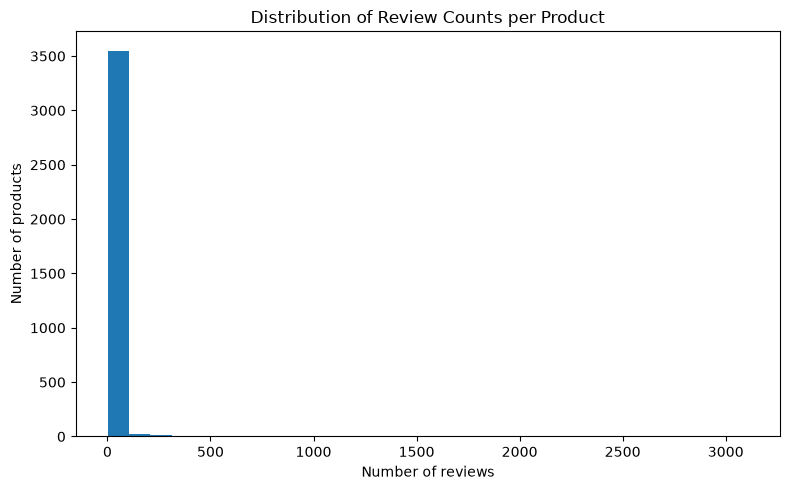

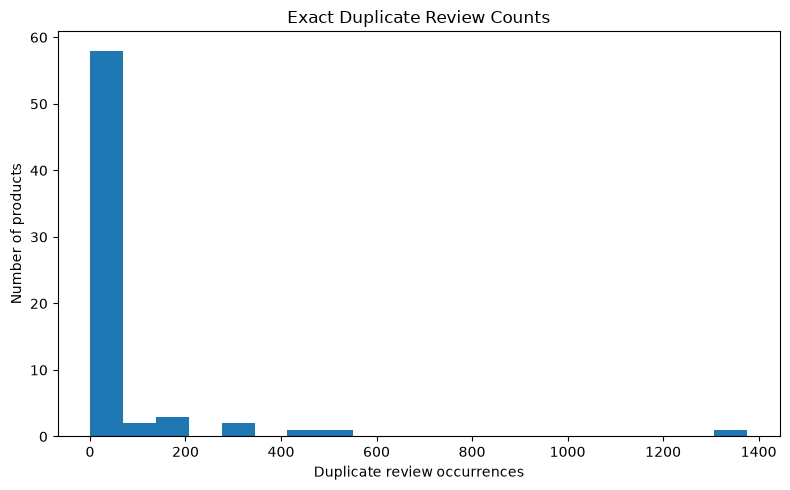

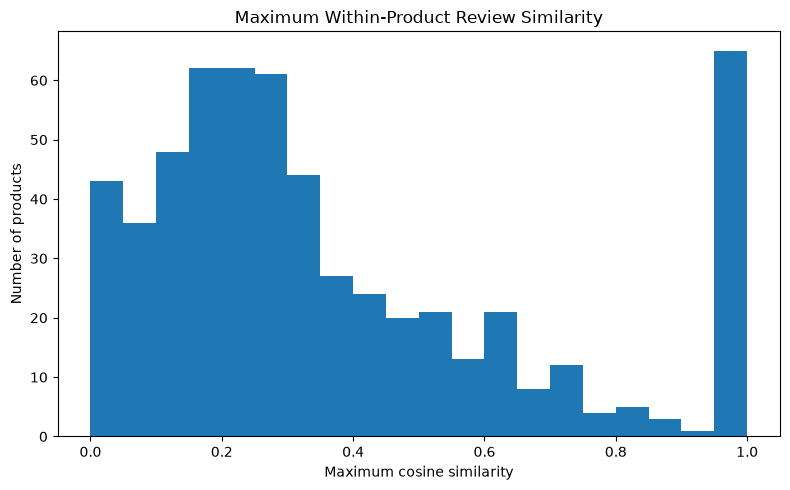

In [31]:
# 1. Distribution of review counts, excluding zero-review products
plt.figure(figsize=(8, 5))
plt.hist(reviewed_products["review_count"], bins=30)
plt.title("Distribution of Review Counts per Product")
plt.xlabel("Number of reviews")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()


# 2. Products with exact duplicate reviews
duplicate_products = reviewed_products[
    reviewed_products["exact_duplicate_review_count"] > 0
]

plt.figure(figsize=(8, 5))
plt.hist(duplicate_products["exact_duplicate_review_count"], bins=20)
plt.title("Exact Duplicate Review Counts")
plt.xlabel("Duplicate review occurrences")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()


# 3. Maximum within-product text similarity
similarity_values = reviewed_products[
    "max_intra_listing_similarity"
].dropna()

plt.figure(figsize=(8, 5))
plt.hist(similarity_values, bins=20)
plt.title("Maximum Within-Product Review Similarity")
plt.xlabel("Maximum cosine similarity")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()

In [32]:
# Step 11: Marketplace-wise NLP feature comparison

df = saved_features.copy()

# Aggregate product-level features by marketplace
marketplace_summary = (
    df.groupby("marketplace")
    .agg(
        total_products=("canonical_product_id", "nunique"),
        products_with_reviews=(
            "review_count",
            lambda x: (x > 0).sum()
        ),
        total_reviews=("review_count", "sum"),
        products_with_duplicates=(
            "exact_duplicate_review_count",
            lambda x: (x > 0).sum()
        ),
        products_with_high_similarity=(
            "high_similarity_pair_count",
            lambda x: (x > 0).sum()
        ),
        products_with_discordance=(
            "polar_discordance_count",
            lambda x: (x > 0).sum()
        ),
        mean_reviews_per_product=("review_count", "mean"),
        mean_verified_purchase_ratio=(
            "verified_purchase_ratio", "mean"
        ),
        mean_polar_discordance_ratio=(
            "polar_discordance_ratio", "mean"
        ),
    )
    .reset_index()
)

display(marketplace_summary.round(3))

,marketplace,total_products,products_with_reviews,total_reviews,products_with_duplicates,products_with_high_similarity,products_with_discordance,mean_reviews_per_product,mean_verified_purchase_ratio,mean_polar_discordance_ratio
0,amazon,5466,3378,10651,7,17,395,1.949,0.829,0.058
1,bestbuy,249,249,44965,61,15,177,180.582,1.000,0.067
2,walmart,22074,0,0,0,0,0,0.000,NaN,NaN


In [33]:
# Step 12: Normalized marketplace-level rates

df = saved_features.copy()

marketplace_rates = (
    df.groupby("marketplace")
    .agg(
        total_products=("canonical_product_id", "nunique"),
        reviewed_products=(
            "review_count",
            lambda x: (x > 0).sum()
        ),
        products_with_duplicates=(
            "exact_duplicate_review_count",
            lambda x: (x > 0).sum()
        ),
        products_with_high_similarity=(
            "high_similarity_pair_count",
            lambda x: (x > 0).sum()
        ),
        products_with_discordance=(
            "polar_discordance_count",
            lambda x: (x > 0).sum()
        ),
    )
    .reset_index()
)

# Calculate percentages using all products in each marketplace
marketplace_rates["reviewed_product_pct"] = (
    marketplace_rates["reviewed_products"]
    / marketplace_rates["total_products"] * 100
)

marketplace_rates["duplicate_product_pct"] = (
    marketplace_rates["products_with_duplicates"]
    / marketplace_rates["total_products"] * 100
)

marketplace_rates["high_similarity_product_pct"] = (
    marketplace_rates["products_with_high_similarity"]
    / marketplace_rates["total_products"] * 100
)

marketplace_rates["discordance_product_pct"] = (
    marketplace_rates["products_with_discordance"]
    / marketplace_rates["total_products"] * 100
)

display(marketplace_rates.round(2))

,marketplace,total_products,reviewed_products,products_with_duplicates,products_with_high_similarity,products_with_discordance,reviewed_product_pct,duplicate_product_pct,high_similarity_product_pct,discordance_product_pct
0,amazon,5466,3378,7,17,395,61.8,0.13,0.31,7.23
1,bestbuy,249,249,61,15,177,100.0,24.50,6.02,71.08
2,walmart,22074,0,0,0,0,0.0,0.00,0.00,0.00


In [34]:

import pandas as pd
import matplotlib.pyplot as plt

df = saved_features.copy()

# Use products that have at least one review
reviewed = df[df["review_count"] > 0].copy()

# Group products by review volume
reviewed["review_volume_group"] = pd.cut(
    reviewed["review_count"],
    bins=[0, 1, 5, 20, float("inf")],
    labels=["1 review", "2–5 reviews", "6–20 reviews", "21+ reviews"],
    include_lowest=True
)

# Summarize review-pattern signals by review-volume group
relationship_summary = (
    reviewed.groupby("review_volume_group", observed=False)
    .agg(
        product_count=("canonical_product_id", "nunique"),
        mean_review_count=("review_count", "mean"),
        pct_with_duplicates=(
            "exact_duplicate_review_count",
            lambda x: (x > 0).mean() * 100
        ),
        pct_with_high_similarity=(
            "high_similarity_pair_count",
            lambda x: (x > 0).mean() * 100
        ),
        pct_with_discordance=(
            "polar_discordance_count",
            lambda x: (x > 0).mean() * 100
        ),
    )
    .reset_index()
)

display(relationship_summary.round(2))


,review_volume_group,product_count,mean_review_count,pct_with_duplicates,pct_with_high_similarity,pct_with_discordance
0,1 review,3047,1.00,0.00,0.00,5.74
1,2–5 reviews,85,2.76,3.53,0.00,15.29
2,6–20 reviews,195,13.25,2.05,1.54,56.41
3,21+ reviews,300,165.84,20.33,9.67,91.33


## Step 14: NLP Feature Engineering — Summary and Limitations

### Objective
Create a product-level dataset that summarizes review patterns for the AI-Based Marketplace Analyzer.

### Input datasets
- `canonical_products.parquet`
- `canonical_reviews.parquet`

### Engineered features

**1. Review volume**
- `review_count`
- `listing_state`

**2. Rating and purchase verification**
- `average_rating`
- `rating_std_dev`
- `valid_rating_count`
- `verified_review_count`
- `unverified_review_count`
- `known_verification_count`
- `verified_purchase_ratio`

**3. Sentiment–rating discordance**
- `eligible_sentiment_review_count`
- `polar_discordance_count`
- `polar_discordance_ratio`

**4. Review repetition and similarity**
- `exact_duplicate_review_count`
- `max_intra_listing_similarity`
- `high_similarity_pair_count`
- `similarity_pairs_evaluated`
- `similarity_truncated`

### Interpretation
These features describe review activity and potentially suspicious patterns. They do not independently establish whether a review or product is fraudulent.

### Limitations
- The canonical `ground_truth_label` column was reported to be missing for all reviews, so it cannot currently supply supervised training labels.
- Products without reviews provide no review-based evidence.
- Similarity and sentiment features can be unavailable when there is insufficient usable text.
- Similarity calculations are capped at 200 reviews per product in the current implementation.
- Marketplace differences may reflect catalog composition and review volume, not fraud prevalence.

### Next work
Review feature quality, verify calculations against the source reviews, and document the confirmed results before integrating the features into the broader risk engine.

In [35]:

import pandas as pd
import numpy as np
from pathlib import Path

# Load the original review records and engineered features
cwd = Path.cwd().resolve()
if (cwd / "data" / "processed").is_dir():
    project_root = cwd
elif (cwd.parent / "data" / "processed").is_dir():
    project_root = cwd.parent
else:
    raise FileNotFoundError(f"Could not locate project root from {cwd}")

reviews_source = pd.read_parquet(
    project_root / "data" / "processed" / "canonical_reviews.parquet"
)

features_source = pd.read_parquet(
    project_root / "data" / "processed" / "product_review_features.parquet"
)

# Independently recalculate review counts from the raw reviews
source_review_counts = (
    reviews_source.groupby("canonical_product_id")
    .size()
    .rename("source_review_count")
)

# Join source counts to saved product features
count_audit = features_source[
    ["canonical_product_id", "review_count"]
].merge(
    source_review_counts,
    on="canonical_product_id",
    how="left",
    validate="one_to_one"
)

count_audit["source_review_count"] = (
    count_audit["source_review_count"].fillna(0).astype("int64")
)

count_audit["count_matches"] = (
    count_audit["review_count"] == count_audit["source_review_count"]
)

print("Products checked:", len(count_audit))
print("Matching review counts:", count_audit["count_matches"].sum())
print("Mismatched review counts:", (~count_audit["count_matches"]).sum())

# Show mismatches if any exist
display(
    count_audit.loc[
        ~count_audit["count_matches"]
    ].head(20)
)

assert count_audit["count_matches"].all(), (
    "Review-count audit failed. Inspect the mismatched products above."
)

print("\nReview-count source audit passed!")


Products checked: 27789
Matching review counts: 27789
Mismatched review counts: 0


,canonical_product_id,review_count,source_review_count,count_matches



Review-count source audit passed!


In [36]:

# Step 16: Audit rating and verification features

# Use the original canonical review records
audit_reviews = reviews_source.copy()

audit_reviews["rating"] = pd.to_numeric(
    audit_reviews["rating"], errors="coerce"
)

# Recalculate rating statistics
rating_audit = (
    audit_reviews.groupby("canonical_product_id")
    .agg(
        audit_average_rating=("rating", "mean"),
        audit_rating_std_dev=("rating", "std"),
        audit_valid_rating_count=("rating", "count"),
    )
    .reset_index()
)

# Recreate verification categories
verification = audit_reviews["verified_purchase"]

if pd.api.types.is_bool_dtype(verification):
    audit_reviews["verification_status"] = (
        verification.map({
            True: "VERIFIED",
            False: "UNVERIFIED"
        }).fillna("UNKNOWN")
    )
else:
    normalized = verification.astype("string").str.strip().str.lower()

    audit_reviews["verification_status"] = np.select(
        [
            normalized.isin(["true", "1", "yes", "verified"]),
            normalized.isin(["false", "0", "no", "unverified"]),
        ],
        ["VERIFIED", "UNVERIFIED"],
        default="UNKNOWN"
    )

verification_audit = (
    audit_reviews.assign(
        verified=(audit_reviews["verification_status"] == "VERIFIED"),
        unverified=(audit_reviews["verification_status"] == "UNVERIFIED"),
        known=(audit_reviews["verification_status"] != "UNKNOWN"),
    )
    .groupby("canonical_product_id")
    .agg(
        audit_verified_review_count=("verified", "sum"),
        audit_unverified_review_count=("unverified", "sum"),
        audit_known_verification_count=("known", "sum"),
    )
    .reset_index()
)

# Merge independently recalculated values
audit = (
    features_source
    .merge(rating_audit, on="canonical_product_id", how="left",
           validate="one_to_one")
    .merge(verification_audit, on="canonical_product_id", how="left",
           validate="one_to_one")
)

# Compare counts exactly
count_checks = {
    "valid_rating_count": "audit_valid_rating_count",
    "verified_review_count": "audit_verified_review_count",
    "unverified_review_count": "audit_unverified_review_count",
    "known_verification_count": "audit_known_verification_count",
}

for saved_col, audit_col in count_checks.items():
    saved_values = audit[saved_col].fillna(0).astype("int64")
    recalculated_values = audit[audit_col].fillna(0).astype("int64")

    print(
        f"{saved_col}:",
        "PASS" if saved_values.equals(recalculated_values) else "FAIL"
    )

# Compare numeric rating statistics, allowing tiny floating-point differences
for saved_col, audit_col in [
    ("average_rating", "audit_average_rating"),
    ("rating_std_dev", "audit_rating_std_dev"),
]:
    matches = np.isclose(
        audit[saved_col].to_numpy(dtype=float, na_value=np.nan),
        audit[audit_col].to_numpy(dtype=float, na_value=np.nan),
        rtol=1e-7,
        atol=1e-8,
        equal_nan=True,
    )
    print(f"{saved_col}:", "PASS" if matches.all() else "FAIL")

print("\nAudit sample:")
display(audit[
    [
        "canonical_product_id",
        "average_rating",
        "audit_average_rating",
        "valid_rating_count",
        "audit_valid_rating_count",
        "verified_review_count",
        "audit_verified_review_count",
    ]
].head(10))


valid_rating_count: PASS
verified_review_count: PASS
unverified_review_count: PASS
known_verification_count: PASS
average_rating: PASS
rating_std_dev: PASS

Audit sample:


,canonical_product_id,average_rating,audit_average_rating,valid_rating_count,audit_valid_rating_count,verified_review_count,audit_verified_review_count
0,amazon_B00V5CDD9C,2.607143,2.607143,28,28.0,27,27.0
1,amazon_B085B5S92V,3.975000,3.975000,40,40.0,37,37.0
2,amazon_B088G1ZJHP,3.975000,3.975000,40,40.0,40,40.0
3,amazon_B01M1OFZOG,4.150000,4.150000,40,40.0,34,34.0
4,amazon_B00JBUJ6QO,2.727273,2.727273,11,11.0,9,9.0
5,amazon_B00KEUT6BA,3.375000,3.375000,40,40.0,40,40.0
6,amazon_B077TBSVK8,4.125000,4.125000,40,40.0,40,40.0
7,amazon_B01F8AWWAW,4.583333,4.583333,12,12.0,12,12.0
8,amazon_B08NHTHD2G,2.525000,2.525000,40,40.0,40,40.0
9,amazon_B084QB5Q5G,3.750000,3.750000,40,40.0,39,39.0


In [37]:


# Step 17: Audit sentiment-rating discordance features

import sys
from pathlib import Path
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Ensure the project root is available
# ------------------------------------------------------------

cwd = Path.cwd().resolve()

if (cwd / "data" / "processed").is_dir():
    project_root = cwd
elif (cwd.parent / "data" / "processed").is_dir():
    project_root = cwd.parent
else:
    raise FileNotFoundError(
        f"Could not locate project root from {cwd}"
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.nlp.review_analysis import (
    get_sentiment_compound,
    is_polar_discordance,
)

# ------------------------------------------------------------
# 2. Prepare the source reviews
# ------------------------------------------------------------

# Resolve source reviews and features from active session or parquet files
if "reviews_source" in globals():
    source_reviews = reviews_source
elif "reviews" in globals():
    source_reviews = reviews
else:
    source_reviews = pd.read_parquet(
        project_root / "data" / "processed" / "canonical_reviews.parquet"
    )

if "features_source" in globals():
    source_features = features_source
elif "saved_features" in globals():
    source_features = saved_features
elif "product_review_features" in globals():
    source_features = product_review_features
else:
    source_features = pd.read_parquet(
        project_root / "data" / "processed" / "product_review_features.parquet"
    )

reviews_source = source_reviews
features_source = source_features

audit_reviews = reviews_source.copy()

audit_reviews["review_text"] = (
    audit_reviews["review_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

audit_reviews["rating"] = pd.to_numeric(
    audit_reviews["rating"],
    errors="coerce",
)

# Same eligibility criteria as Step 3:
# valid rating + review text containing at least 4 characters.

eligible = (
    audit_reviews["rating"].notna()
    & audit_reviews["review_text"].str.len().ge(4)
)

audit_reviews["audit_sentiment_eligible"] = eligible
audit_reviews["audit_polar_discordance"] = False

# ------------------------------------------------------------
# 3. Independently recalculate sentiment discordance
# ------------------------------------------------------------

eligible_indices = audit_reviews.index[eligible]

audit_reviews.loc[
    eligible_indices, "audit_polar_discordance"
] = [
    is_polar_discordance(
        rating,
        get_sentiment_compound(text),
    )
    for text, rating in zip(
        audit_reviews.loc[eligible_indices, "review_text"],
        audit_reviews.loc[eligible_indices, "rating"],
    )
]

# IMPORTANT:
# is_polar_discordance(rating, sentiment)
# The rating is the FIRST argument, sentiment is the SECOND.

# ------------------------------------------------------------
# 4. Aggregate independently calculated features by product
# ------------------------------------------------------------

sentiment_audit = (
    audit_reviews.groupby("canonical_product_id")
    .agg(
        audit_eligible_sentiment_review_count=(
            "audit_sentiment_eligible", "sum"
        ),
        audit_polar_discordance_count=(
            "audit_polar_discordance", "sum"
        ),
    )
    .reset_index()
)

sentiment_audit["audit_polar_discordance_ratio"] = (
    sentiment_audit["audit_polar_discordance_count"]
    / sentiment_audit[
        "audit_eligible_sentiment_review_count"
    ].replace(0, np.nan)
)

# ------------------------------------------------------------
# 5. Compare independently recalculated results with saved features
# ------------------------------------------------------------

audit = features_source.merge(
    sentiment_audit,
    on="canonical_product_id",
    how="left",
    validate="one_to_one",
)

count_columns = [
    "audit_eligible_sentiment_review_count",
    "audit_polar_discordance_count",
]

audit[count_columns] = (
    audit[count_columns].fillna(0).astype("int64")
)

count_checks = [
    (
        "eligible_sentiment_review_count",
        "audit_eligible_sentiment_review_count",
    ),
    (
        "polar_discordance_count",
        "audit_polar_discordance_count",
    ),
]

print("SENTIMENT DISCORDANCE FEATURE AUDIT")
print("=" * 55)

for saved_col, recalculated_col in count_checks:
    matches = (
        audit[saved_col].fillna(0).astype("int64")
        == audit[recalculated_col]
    )

    print(
        f"{saved_col}: "
        f"{'PASS' if matches.all() else 'FAIL'} "
        f"({matches.sum()}/{len(matches)} products match)"
    )

# Compare ratios, treating NaN == NaN for unavailable ratios.
saved_ratio = audit[
    "polar_discordance_ratio"
].to_numpy(dtype=float, na_value=np.nan)

recalculated_ratio = audit[
    "audit_polar_discordance_ratio"
].to_numpy(dtype=float, na_value=np.nan)

ratio_matches = np.isclose(
    saved_ratio,
    recalculated_ratio,
    rtol=1e-7,
    atol=1e-8,
    equal_nan=True,
)

print(
    "polar_discordance_ratio: "
    f"{'PASS' if ratio_matches.all() else 'FAIL'} "
    f"({ratio_matches.sum()}/{len(ratio_matches)} products match)"
)

# ------------------------------------------------------------
# 6. Overall summary and sample
# ------------------------------------------------------------

print("\nOVERALL SUMMARY")
print("-" * 55)
print("Source reviews:", f"{len(audit_reviews):,}")
print("Eligible reviews:", f"{int(eligible.sum()):,}")
print(
    "Polar discordant reviews:",
    f"{int(audit_reviews['audit_polar_discordance'].sum()):,}",
)
print("Products audited:", f"{len(audit):,}")

print("\nAudit sample:")

display(
    audit[
        [
            "canonical_product_id",
            "eligible_sentiment_review_count",
            "audit_eligible_sentiment_review_count",
            "polar_discordance_count",
            "audit_polar_discordance_count",
            "polar_discordance_ratio",
            "audit_polar_discordance_ratio",
        ]
    ].head(10)
)


SENTIMENT DISCORDANCE FEATURE AUDIT
eligible_sentiment_review_count: PASS (27789/27789 products match)
polar_discordance_count: PASS (27789/27789 products match)
polar_discordance_ratio: PASS (27789/27789 products match)

OVERALL SUMMARY
-------------------------------------------------------
Source reviews: 55,616
Eligible reviews: 55,607
Polar discordant reviews: 2,588
Products audited: 27,789

Audit sample:


,canonical_product_id,eligible_sentiment_review_count,audit_eligible_sentiment_review_count,polar_discordance_count,audit_polar_discordance_count,polar_discordance_ratio,audit_polar_discordance_ratio
0,amazon_B00V5CDD9C,28,28,1,1,0.035714,0.035714
1,amazon_B085B5S92V,40,40,5,5,0.125000,0.125000
2,amazon_B088G1ZJHP,40,40,4,4,0.100000,0.100000
3,amazon_B01M1OFZOG,40,40,2,2,0.050000,0.050000
4,amazon_B00JBUJ6QO,11,11,1,1,0.090909,0.090909
5,amazon_B00KEUT6BA,40,40,2,2,0.050000,0.050000
6,amazon_B077TBSVK8,40,40,3,3,0.075000,0.075000
7,amazon_B01F8AWWAW,12,12,0,0,0.000000,0.000000
8,amazon_B08NHTHD2G,40,40,10,10,0.250000,0.250000
9,amazon_B084QB5Q5G,40,40,1,1,0.025000,0.025000


In [38]:

# Step 18A: Audit exact duplicate review counts

import re
import numpy as np
import pandas as pd

audit_reviews = reviews_source.copy()

# Use the same text normalization rule as the feature engineering step
audit_reviews["normalized_text"] = (
    audit_reviews["review_text"]
    .fillna("")
    .astype(str)
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Exclude empty and short reviews, matching the original minimum length
eligible_text = audit_reviews[
    audit_reviews["normalized_text"].str.len() >= 4
].copy()

# Count occurrences beyond the first copy of each normalized review
duplicate_audit = (
    eligible_text.groupby("canonical_product_id")["normalized_text"]
    .apply(lambda text: int(text.duplicated().sum()))
    .rename("audit_exact_duplicate_review_count")
    .reset_index()
)

audit = features_source[
    ["canonical_product_id", "exact_duplicate_review_count"]
].merge(
    duplicate_audit,
    on="canonical_product_id",
    how="left",
    validate="one_to_one"
)

audit["audit_exact_duplicate_review_count"] = (
    audit["audit_exact_duplicate_review_count"]
    .fillna(0)
    .astype("int64")
)

matches = (
    audit["exact_duplicate_review_count"]
    == audit["audit_exact_duplicate_review_count"]
)

print("Products checked:", len(audit))
print("Matching duplicate counts:", matches.sum())
print("Mismatched duplicate counts:", (~matches).sum())

display(audit.loc[~matches].head(20))

assert matches.all(), (
    "Duplicate-count audit failed. Inspect the mismatched products."
)

print("\nExact duplicate-count audit passed!")


Products checked: 27789
Matching duplicate counts: 27789
Mismatched duplicate counts: 0


,canonical_product_id,exact_duplicate_review_count,audit_exact_duplicate_review_count



Exact duplicate-count audit passed!


In [39]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

SIMILARITY_THRESHOLD = 0.80
MIN_TEXT_LENGTH = 4
MAX_REVIEWS_PER_PRODUCT = 200

def independently_recalculate_similarity(texts):
    # Normalize text using the original feature-engineering rule
    texts = (
        pd.Series(texts)
        .fillna("")
        .astype(str)
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    texts = texts[texts.str.len() >= MIN_TEXT_LENGTH].tolist()

    if len(texts) < 2:
        return {
            "audit_max_similarity": np.nan,
            "audit_high_similarity_pair_count": 0,
            "audit_similarity_pairs_evaluated": 0,
            "audit_similarity_truncated": False,
        }

    truncated = len(texts) > MAX_REVIEWS_PER_PRODUCT
    texts = texts[:MAX_REVIEWS_PER_PRODUCT]

    try:
        vectorizer = TfidfVectorizer(
            stop_words="english",
            ngram_range=(1, 2),
            min_df=1,
            max_features=1000,
        )
        matrix = vectorizer.fit_transform(texts)
        similarity_matrix = np.clip(cosine_similarity(matrix), 0.0, 1.0)
    except ValueError:
        return {
            "audit_max_similarity": np.nan,
            "audit_high_similarity_pair_count": 0,
            "audit_similarity_pairs_evaluated": 0,
            "audit_similarity_truncated": truncated,
        }

    upper_i, upper_j = np.triu_indices(len(texts), k=1)
    scores = similarity_matrix[upper_i, upper_j]

    # Exclude exact normalized duplicates from the high-similarity pair count
    distinct_text_pairs = np.array([
        texts[i] != texts[j]
        for i, j in zip(upper_i, upper_j)
    ])

    return {
        "audit_max_similarity": float(scores.max()) if len(scores) else np.nan,
        "audit_high_similarity_pair_count": int(
            ((scores >= SIMILARITY_THRESHOLD) & distinct_text_pairs).sum()
        ),
        "audit_similarity_pairs_evaluated": len(scores),
        "audit_similarity_truncated": truncated,
    }


# Recalculate similarity features from the original review text
audit_rows = []

for product_id, group in reviews_source.groupby("canonical_product_id"):
    result = independently_recalculate_similarity(group["review_text"])
    result["canonical_product_id"] = product_id
    audit_rows.append(result)

similarity_audit = pd.DataFrame(audit_rows)

audit = features_source.merge(
    similarity_audit,
    on="canonical_product_id",
    how="left",
    validate="one_to_one",
)

# Products with no source reviews have no similarity pairs
for col in [
    "audit_high_similarity_pair_count",
    "audit_similarity_pairs_evaluated",
]:
    audit[col] = audit[col].fillna(0).astype("int64")

audit["audit_similarity_truncated"] = (
    audit["audit_similarity_truncated"].fillna(False).astype(bool)
)

# Compare count and truncation features exactly
for saved_col, audit_col in [
    ("high_similarity_pair_count", "audit_high_similarity_pair_count"),
    ("similarity_pairs_evaluated", "audit_similarity_pairs_evaluated"),
    ("similarity_truncated", "audit_similarity_truncated"),
]:
    matches = audit[saved_col].equals(audit[audit_col])
    print(f"{saved_col}:", "PASS" if matches else "FAIL")

# Compare maximum similarity with a floating-point tolerance
similarity_matches = np.isclose(
    audit["max_intra_listing_similarity"].to_numpy(dtype=float, na_value=np.nan),
    audit["audit_max_similarity"].to_numpy(dtype=float, na_value=np.nan),
    rtol=1e-6,
    atol=1e-7,
    equal_nan=True,
)

print(
    "max_intra_listing_similarity:",
    "PASS" if similarity_matches.all() else "FAIL",
    f"({similarity_matches.sum()}/{len(similarity_matches)} products match)",
)


high_similarity_pair_count: PASS
similarity_pairs_evaluated: PASS
similarity_truncated: PASS
max_intra_listing_similarity: PASS (27789/27789 products match)


In [40]:

# Step 19: NLP Feature Audit Summary

audit_results = {
    "Review counts": "Run Step 15 and confirm zero mismatches",
    "Ratings and verification": "Run Step 16 and confirm all PASS",
    "Sentiment discordance": "Run Step 17 and confirm all PASS",
    "Exact duplicate counts": "Run Step 18A and confirm zero mismatches",
    "Similarity features": "Run Step 18B and confirm all PASS",
}

print("NLP FEATURE AUDIT CHECKLIST")
print("=" * 45)

for check, instruction in audit_results.items():
    print(f"{check}: {instruction}")

print("\nSaved feature file:")
print(str(project_root / "data" / "processed" / "product_review_features.parquet"))

print("\nFeature dataset shape:", features_source.shape)
print("Unique product IDs:", features_source["canonical_product_id"].nunique())
print("Duplicate product IDs:", features_source["canonical_product_id"].duplicated().sum())


NLP FEATURE AUDIT CHECKLIST
Review counts: Run Step 15 and confirm zero mismatches
Ratings and verification: Run Step 16 and confirm all PASS
Sentiment discordance: Run Step 17 and confirm all PASS
Exact duplicate counts: Run Step 18A and confirm zero mismatches
Similarity features: Run Step 18B and confirm all PASS

Saved feature file:
C:\Users\shruti\Desktop\project\ai-based-marketplace-analyzer\data\processed\product_review_features.parquet

Feature dataset shape: (27789, 21)
Unique product IDs: 27789
Duplicate product IDs: 0


## Step 20: Review of the Existing NLP Module

**Objective:** Understand the existing NLP implementation before integrating the newly engineered product-level features.

File: `src/nlp/review_analysis.py`

Functions and components to inspect:
- `get_sentiment_compound`
- `is_polar_discordance`
- `ProductReviewAnalyzer.analyze_reviews`
- `batch_analyze_dataset`

Review questions:
1. What input data does each function expect?
2. What output does each function return?
3. How are empty reviews and missing values handled?
4. How are duplicate reviews and similarity calculated?
5. How are products with zero or one review handled?
6. Which outputs are consumed by the existing risk engine?
7. Which newly engineered features are not yet represented in the existing output?